# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.constants import VTI
from sharpelab_nb.thermometry import temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260716-QC0426'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.024 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.11s
Sample:    1.167 K
Vaporizer: 0.942 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.08s


Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::24::INSTR')  # <-- verify address — top-gate Keithley
# k_2400_tg.mode.set('VOLT')
# k_2400_tg.volt.set(0)
# k_2400_tg.rangei.set(1e-6)
# k_2400_tg.rangev.set(21)
k_2400_tg.volt.step = 0.005
k_2400_tg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.02s


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::1::INSTR')  # <-- verify address — back-gate Keithley
# k_2400_bg.mode.set('VOLT')
# k_2400_bg.volt.set(0)
# k_2400_bg.rangei.set(1e-6)
# k_2400_bg.rangev.set(21)
k_2400_bg.volt.step = 0.005
k_2400_bg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.02s


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -3.0, +3.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 50.0  # K — session setpoint cap, card ruling 2026-07-16    # <-- validate
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T2",  # drive injection contact    # <-- validate
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4",  # <-- validate
    "sr2": "B4-B5",  # <-- validate
    "sr3": "T5-B6",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T2", "drain": "B7",
    "sr1+": "T3", "sr1-": "T4",
    "sr2+": "B4", "sr2-": "B5",
    "sr3+": "T5", "sr3-": "B6",
}

# HERA — QC0426 session start (2026-07-16)

## HERA — session-start VERIFY (read-only)

Brief's VERIFY checklist as one cell: magnet at zero (measured readback + status), base T with logfile-freshness guard (a frozen worker reads a plausible value — rig card), DC205 on RNGE 2 / output on / 0 V, PS heater + output enabled, gate readbacks, committed validators echoed against the card numbers (TG ±3.0, BG ±4.5, Si ±50 V, |B| ≤ 8 T, T ≤ 50 K), and the lock-in τ / filter-slope / sensitivity record (operator-set, not in run snapshots — this is the bring-up record). No instrument writes. ~10 s.

If all asserts pass it prints **VERIFY: all green** — then your "go for autonomy" engages E1 (first E1 execute will be the read-only kernel-binding probe, then gate C liveness).


In [16]:
# HERA — session-start VERIFY. Read-only: no instrument writes.
import os, time
from pathlib import Path

# --- magnet at zero, PS heater / output ---
B = magnet.field()
print(f"B (measured)     : {B:+.4f} T | status: {magnet._status()['field']}")
assert abs(B) < 0.02, f"magnet not at zero: {B} T"
ps, oe = magnet.persistent_switch_on(), magnet.output_enabled()
print(f"magnet PS/output : heater {ps}, output {oe}")
assert ps and oe, "PS heater / output not in operating state"

# --- base T + logfile freshness (frozen worker guard) ---
Ts, Tv = T_sample(), T_vaporizer()
p = next(Path(c) for c in VTI.temp_logfile_candidates["T_sample"] if Path(c).exists())
age = time.time() - p.stat().st_mtime
print(f"T_sample         : {Ts:.3f} K (log age {age:.0f} s) | T_vaporizer: {Tv:.3f} K")
assert 1.0 < Ts < 1.5, f"sample T out of base band: {Ts} K"
assert age < 15, f"T logfile stale ({age:.0f} s) — lakeshore worker dead?"

# --- DC205 (Si gate): range 2, output on, 0 V ---
v_si, rng, out = dc205.voltage(), dc205.voltage_range(), dc205.output()
print(f"DC205 (Si)       : {v_si:+.4f} V, range {rng} (need 2), output {out}")
assert int(rng) == 2, "DC205 not on ±100 V range"
assert int(out) == 1, "DC205 output not on"
assert abs(v_si) < 1e-3, f"DC205 not at 0 V: {v_si} V"

# --- gate readbacks (expected: all parked at 0) ---
print(f"gates            : TG {k_tg.volt():+.4f} V, BG {k_bg.volt():+.4f} V, Si {k_si():+.4f} V")

# --- committed validators vs device card ---
for name, par, lo, hi in [
    ("TG", k_2400_tg.volt, -3.0, 3.0),
    ("BG", k_2400_bg.volt, -4.5, 4.5),
    ("Si", dc205.smart_voltage, -50.0, 50.0),
    ("B",  magnet.field, -8.0, 8.0),
]:
    v = par.vals
    print(f"validator {name:2s}     : {v}")
    assert v._min_value == lo and v._max_value == hi, f"{name} validator != card [{lo}, {hi}]"

# --- lock-in settling record (operator-set; snapshots store None — this is the record) ---
for sr in (sr0, sr1, sr2, sr3):
    print(f"{sr.name}: tau {sr.time_constant()} s, slope {sr.filter_slope()} dB/oct, sens {sr.sensitivity()}")

print("\nVERIFY: all green — awaiting 'go for autonomy'")


B (measured)     : +0.0033 T | status: 0.0033396849315068494
magnet PS/output : heater True, output True
T_sample         : 1.166 K (log age 4 s) | T_vaporizer: 0.941 K
DC205 (Si)       : +0.0000 V, range 2 (need 2), output 1
gates            : TG +0.0000 V, BG +0.0000 V, Si +0.0000 V
validator TG     : <Numbers -3.0<=v<=3.0>
validator BG     : <Numbers -4.5<=v<=4.5>
validator Si     : <Numbers -50.0<=v<=50.0>
validator B      : <Numbers -8.0<=v<=8.0>


sr0: tau 0.3 s, slope 24 dB/oct, sens 0.05
sr1: tau 0.3 s, slope 24 dB/oct, sens 2e-05
sr2: tau 0.3 s, slope 24 dB/oct, sens 2e-05
sr3: tau 0.3 s, slope 24 dB/oct, sens 5e-05

VERIFY: all green — awaiting 'go for autonomy'


## HERA — E1 kernel-binding probe

Grant received ('go for autonomy', recorded in session_notes.md). First E1 execute per the brief: read-only namespace probe confirming this nb-collab connection is bound to the operator's instrument-carrying kernel. No hardware traffic. ~1 s. VERIFY cell executes next.

In [15]:
# HERA — E1 kernel-binding probe (read-only namespace check, no hardware traffic)
import os
print("cwd            :", os.getcwd())
names = ["magnet", "heater", "sr0", "sr1", "sr2", "sr3",
         "k_2400_tg", "k_2400_bg", "dc205", "k_tg", "k_bg", "k_si",
         "T_sample", "T_vaporizer", "meas_config", "WIRING", "cal"]
missing = [n for n in names if n not in globals()]
print("namespace      :", "all bound" if not missing else f"MISSING: {missing}")
assert not missing, f"not the instrument-carrying kernel: missing {missing}"
print("k_tg -> %s | k_bg -> %s | k_si -> %s" % (k_tg.name, k_bg.name, k_si.full_name))
print("T_sample (file):", T_sample(), "K")
print("\nkernel-binding probe: PASS")


cwd            : C:\Users\DGG\VTI_local_data\zack\20260716-QC0426
namespace      : all bound
k_tg -> k_2400_tg | k_bg -> k_2400_bg | k_si -> dc205_smart_voltage
T_sample (file): 1.166 K

kernel-binding probe: PASS


## HERA — Gate C: liveness + gross-safety (`gate-current-sanity-check`)

First-session branch (no designated references — `reentry-baseline` N/A): sweep each metal gate 0 → each card limit, other gates parked at 0, B = 0, watching gate current at pA resolution (`nplci=10`) and all four lock-ins for contact liveness on the provided configuration (source T2, drain B7/sr0, Rxx T3–T4/sr1 + B4–B5/sr2, Rxy T5–B6/sr3). Four legs, one cell each (E1: each leg gets its own armed monitor so a leakage turn-up is killed in-leg): TG→+3.0, TG→−3.0, BG→+4.5, BG→−4.5 V, then a reset cell (nplci back to 1). **Si legs deferred**: the investigation operates at Si = 0 (D ≈ 0 dual-gate work; Si is the contact-doping gate), and the DC205 has no current readback — a ±50 V excursion buys no leakage information and costs ~7 min. If the campaign later needs Si ≠ 0, a liveness leg lands first.

Drive per device card: sr1 sine 0.5 V through 100 MΩ = 5 nA at ≈13 Hz. Dwell: `delay=1` s per the recipe (3.3τ at τ = 0.3 s — liveness-grade, knowingly under the card's 1.2 s classification floor).

**Pass/fail read (per leg)**: lock-in X nonzero and smoothly varying = alive; swept-gate current pA-scale on the capacitive charging slope = safe; parked-gate current at floor = no cross-gate path. Turn-up off the slope → interrupt (try/finally parks the gate), stop, notify.

**Wall-clock**: ~2.1 s/pt (1 s delay + ~1.1 s Keithley NPLC-10 reads, rig-card timing — inherited figure, first in-session calibration comes from leg 1; expect actuals ~5–10% over) × 251 pts ≈ 9 min/leg, ~38 min all four + ramps.


pre: B=+0.0033 T (expect ~0) | T=1.166 K (expect 1.0-1.5)
pre: TG=+0.0000 BG=+0.0000 Si=+0.0000 V (expect all ~0)


drive: sr1 amp 0.5 V, freq 13.142 Hz


2026-07-16 14:59:34,768 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-16 14:59:35,286 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-16 14:59:35,316 [INFO] Starting sweep with ID 0


2026-07-16 14:59:35,318 [INFO] Minimum duration 0h 4m 11s


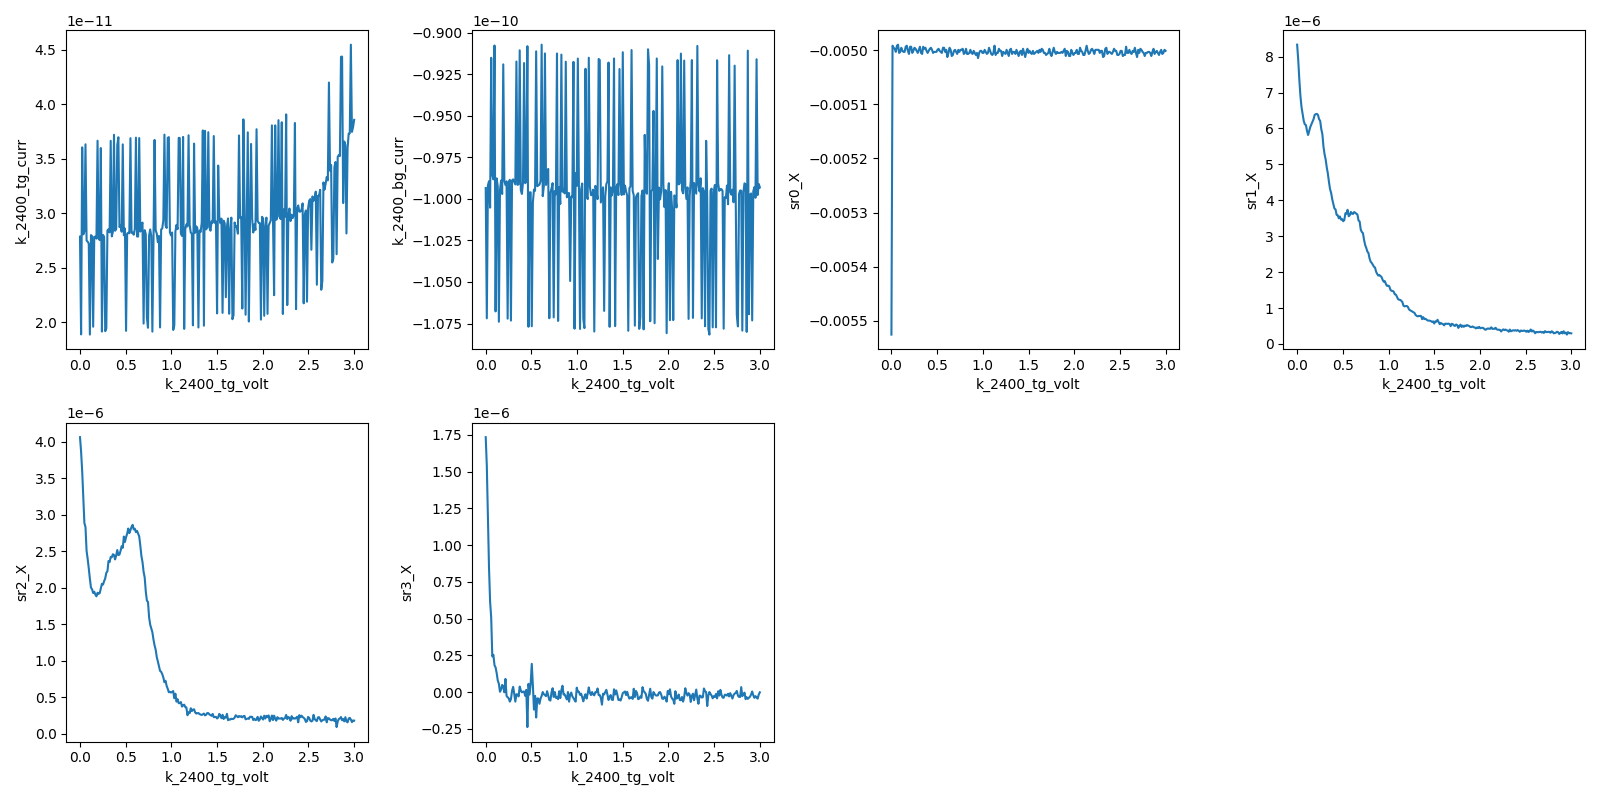

2026-07-16 15:08:33,697 [INFO] Completed in 0h 8m 57s


2026-07-16 15:08:33,698 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\0\data.tsv.gz


2026-07-16 15:08:34,206 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


In [18]:
# --- Gate C leg 1/4: k_tg 0 -> +3.0 V (card limit) --- slug: gate-current-sanity-check
# preconditions (state this cell assumes but does not set)
B, Ts = magnet.field(), T_sample()
print(f"pre: B={B:+.4f} T (expect ~0) | T={Ts:.3f} K (expect 1.0-1.5)")
assert abs(B) < 0.02 and 1.0 < Ts < 1.5, "precondition mismatch — stop"
print(f"pre: TG={k_tg.volt():+.4f} BG={k_bg.volt():+.4f} Si={k_si():+.4f} V (expect all ~0)")
assert abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01 and abs(k_si()) < 0.01

# drive per device card: 0.5 V / 100 MOhm = 5 nA at ~13 Hz (sr1 = drive lock-in)
if abs(sr1.amplitude() - 0.5) > 1e-3:
    sr1.amplitude(0.5)
if not (11 < sr1.frequency() < 15):
    sr1.frequency(13)
print(f"drive: sr1 amp {sr1.amplitude()} V, freq {sr1.frequency():.3f} Hz")

k_tg.nplci(10); k_bg.nplci(10)  # pA-floor gate-current readback; reset cell restores 1

mc = dict(meas_config)
mc["comments"] = "gate C liveness leg 1/4: k_tg 0 -> +3.0 V, other gates 0, B=0, T~1.17 K"
s = sweep.AsyncStation(mc)
s.add_comment('gate-current-sanity-check')
s.add_comment('gate: k_tg; leg: 0 -> +3.0 V (card limit); drive 5 nA @ 13 Hz')
s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)
s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr).fp(k_bg.volt).fp(k_bg.curr)
s.plot(k_tg.volt, k_tg.curr)
s.plot(k_tg.volt, k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)
try:
    s.sweep(k_tg.volt, np.linspace(0, TG_MAX, 251), delay=1)
finally:
    s.ramp(k_tg.volt, 0)


pre: B=+0.0033 T (expect ~0) | T=1.166 K (expect 1.0-1.5)


pre: TG=+0.0000 BG=+0.0000 Si=+0.0000 V (expect all ~0)


drive: sr1 amp 0.5 V, freq 13.142 Hz


2026-07-16 15:09:34,084 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-16 15:09:34,596 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-16 15:09:34,618 [INFO] Starting sweep with ID 1


2026-07-16 15:09:34,619 [INFO] Minimum duration 0h 4m 11s


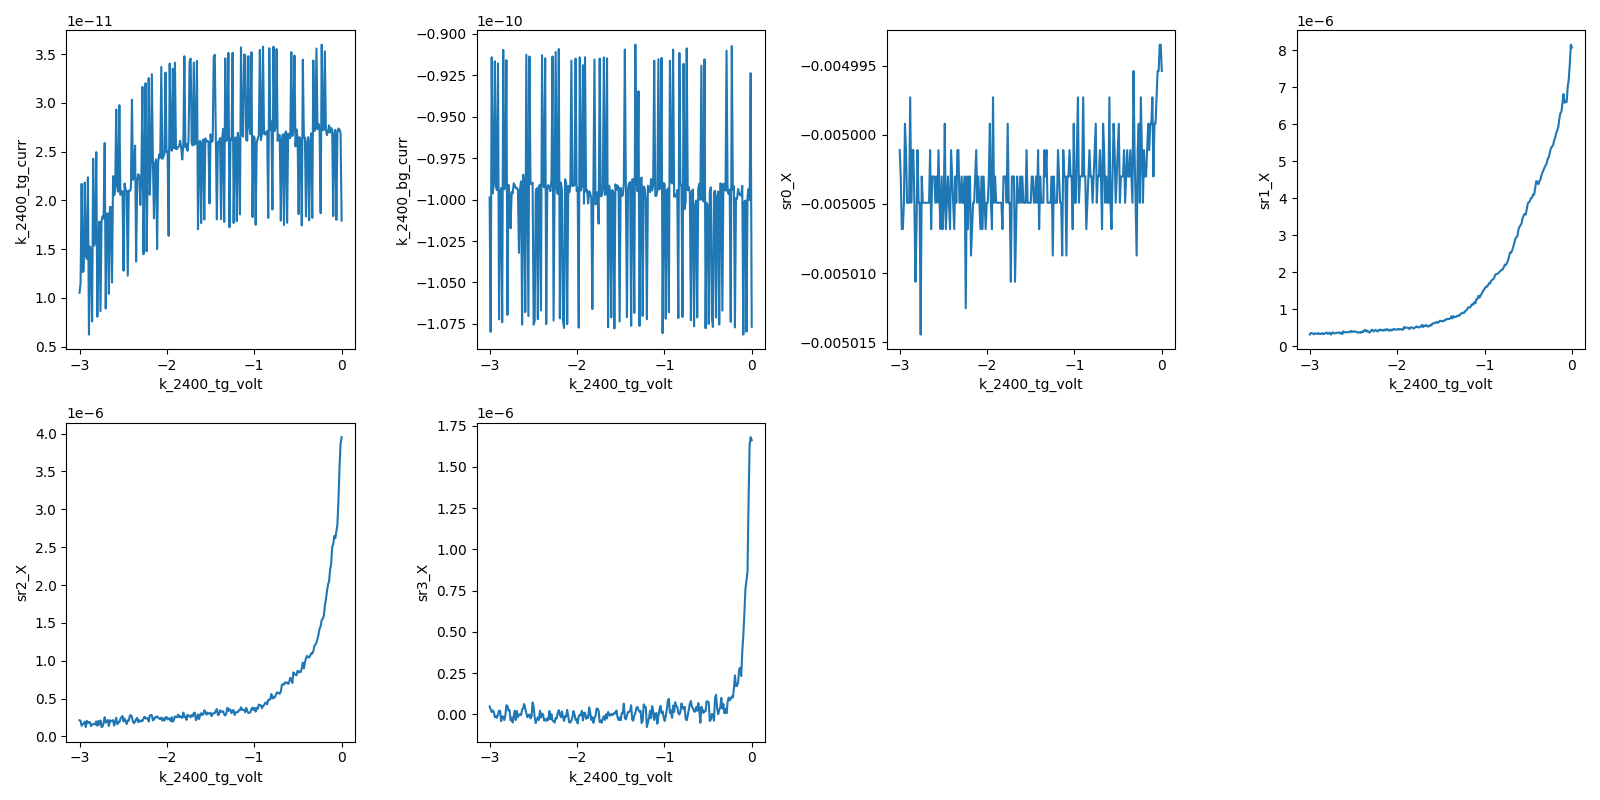

2026-07-16 15:18:24,835 [INFO] Completed in 0h 8m 49s


2026-07-16 15:18:24,835 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\1\data.tsv.gz


2026-07-16 15:18:25,347 [INFO] Ramping k_2400_tg_volt: -3.0 -> 0


In [19]:
# --- Gate C leg 2/4: k_tg 0 -> -3.0 V (card limit) --- slug: gate-current-sanity-check
# preconditions (state this cell assumes but does not set)
B, Ts = magnet.field(), T_sample()
print(f"pre: B={B:+.4f} T (expect ~0) | T={Ts:.3f} K (expect 1.0-1.5)")
assert abs(B) < 0.02 and 1.0 < Ts < 1.5, "precondition mismatch — stop"
print(f"pre: TG={k_tg.volt():+.4f} BG={k_bg.volt():+.4f} Si={k_si():+.4f} V (expect all ~0)")
assert abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01 and abs(k_si()) < 0.01

# drive per device card: 0.5 V / 100 MOhm = 5 nA at ~13 Hz (sr1 = drive lock-in)
if abs(sr1.amplitude() - 0.5) > 1e-3:
    sr1.amplitude(0.5)
if not (11 < sr1.frequency() < 15):
    sr1.frequency(13)
print(f"drive: sr1 amp {sr1.amplitude()} V, freq {sr1.frequency():.3f} Hz")

k_tg.nplci(10); k_bg.nplci(10)  # pA-floor gate-current readback; reset cell restores 1

mc = dict(meas_config)
mc["comments"] = "gate C liveness leg 2/4: k_tg 0 -> -3.0 V, other gates 0, B=0, T~1.17 K"
s = sweep.AsyncStation(mc)
s.add_comment('gate-current-sanity-check')
s.add_comment('gate: k_tg; leg: 0 -> -3.0 V (card limit); drive 5 nA @ 13 Hz')
s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)
s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr).fp(k_bg.volt).fp(k_bg.curr)
s.plot(k_tg.volt, k_tg.curr)
s.plot(k_tg.volt, k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)
try:
    s.sweep(k_tg.volt, np.linspace(0, TG_MIN, 251), delay=1)
finally:
    s.ramp(k_tg.volt, 0)


pre: B=+0.0033 T (expect ~0) | T=1.166 K (expect 1.0-1.5)


pre: TG=+0.0000 BG=+0.0000 Si=+0.0000 V (expect all ~0)


drive: sr1 amp 0.5 V, freq 13.142 Hz


2026-07-16 15:19:16,450 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-16 15:19:16,972 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-16 15:19:16,994 [INFO] Starting sweep with ID 2


2026-07-16 15:19:16,998 [INFO] Minimum duration 0h 4m 11s


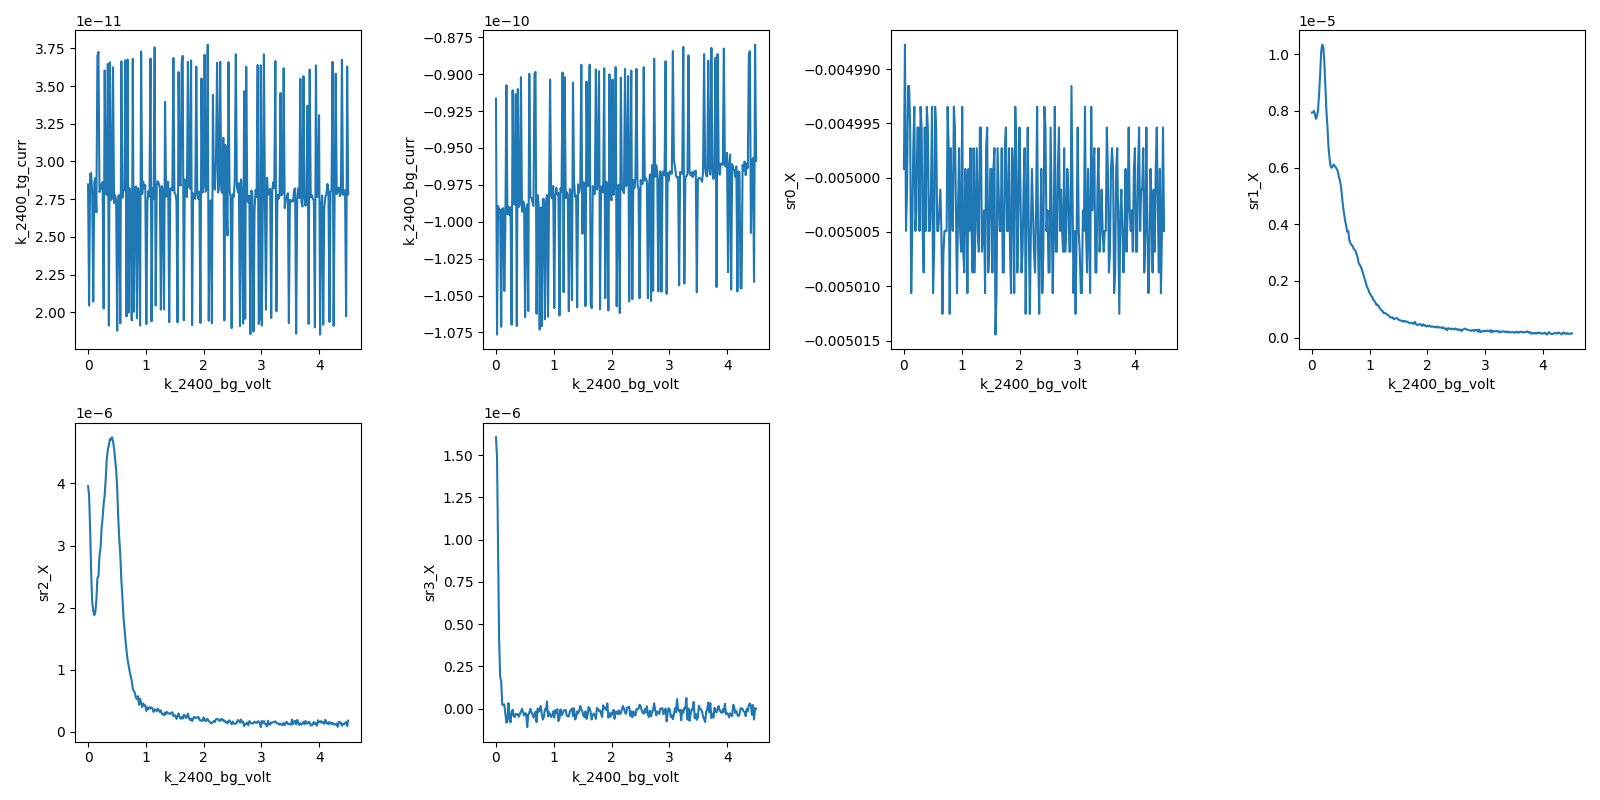

2026-07-16 15:28:11,422 [INFO] Completed in 0h 8m 53s


2026-07-16 15:28:11,423 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\2\data.tsv.gz


2026-07-16 15:28:11,942 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0


In [20]:
# --- Gate C leg 3/4: k_bg 0 -> +4.5 V (card limit) --- slug: gate-current-sanity-check
# preconditions (state this cell assumes but does not set)
B, Ts = magnet.field(), T_sample()
print(f"pre: B={B:+.4f} T (expect ~0) | T={Ts:.3f} K (expect 1.0-1.5)")
assert abs(B) < 0.02 and 1.0 < Ts < 1.5, "precondition mismatch — stop"
print(f"pre: TG={k_tg.volt():+.4f} BG={k_bg.volt():+.4f} Si={k_si():+.4f} V (expect all ~0)")
assert abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01 and abs(k_si()) < 0.01

# drive per device card: 0.5 V / 100 MOhm = 5 nA at ~13 Hz (sr1 = drive lock-in)
if abs(sr1.amplitude() - 0.5) > 1e-3:
    sr1.amplitude(0.5)
if not (11 < sr1.frequency() < 15):
    sr1.frequency(13)
print(f"drive: sr1 amp {sr1.amplitude()} V, freq {sr1.frequency():.3f} Hz")

k_tg.nplci(10); k_bg.nplci(10)  # pA-floor gate-current readback; reset cell restores 1

mc = dict(meas_config)
mc["comments"] = "gate C liveness leg 3/4: k_bg 0 -> +4.5 V, other gates 0, B=0, T~1.17 K"
s = sweep.AsyncStation(mc)
s.add_comment('gate-current-sanity-check')
s.add_comment('gate: k_bg; leg: 0 -> +4.5 V (card limit); drive 5 nA @ 13 Hz')
s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)
s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr).fp(k_bg.volt).fp(k_bg.curr)
s.plot(k_bg.volt, k_tg.curr)
s.plot(k_bg.volt, k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_bg.volt, lia.X)
try:
    s.sweep(k_bg.volt, np.linspace(0, BG_MAX, 251), delay=1)
finally:
    s.ramp(k_bg.volt, 0)


pre: B=+0.0033 T (expect ~0) | T=1.166 K (expect 1.0-1.5)


pre: TG=+0.0000 BG=+0.0000 Si=+0.0000 V (expect all ~0)


drive: sr1 amp 0.5 V, freq 13.142 Hz


2026-07-16 15:28:48,455 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-16 15:28:48,972 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-16 15:28:48,987 [INFO] Starting sweep with ID 3


2026-07-16 15:28:48,988 [INFO] Minimum duration 0h 4m 11s


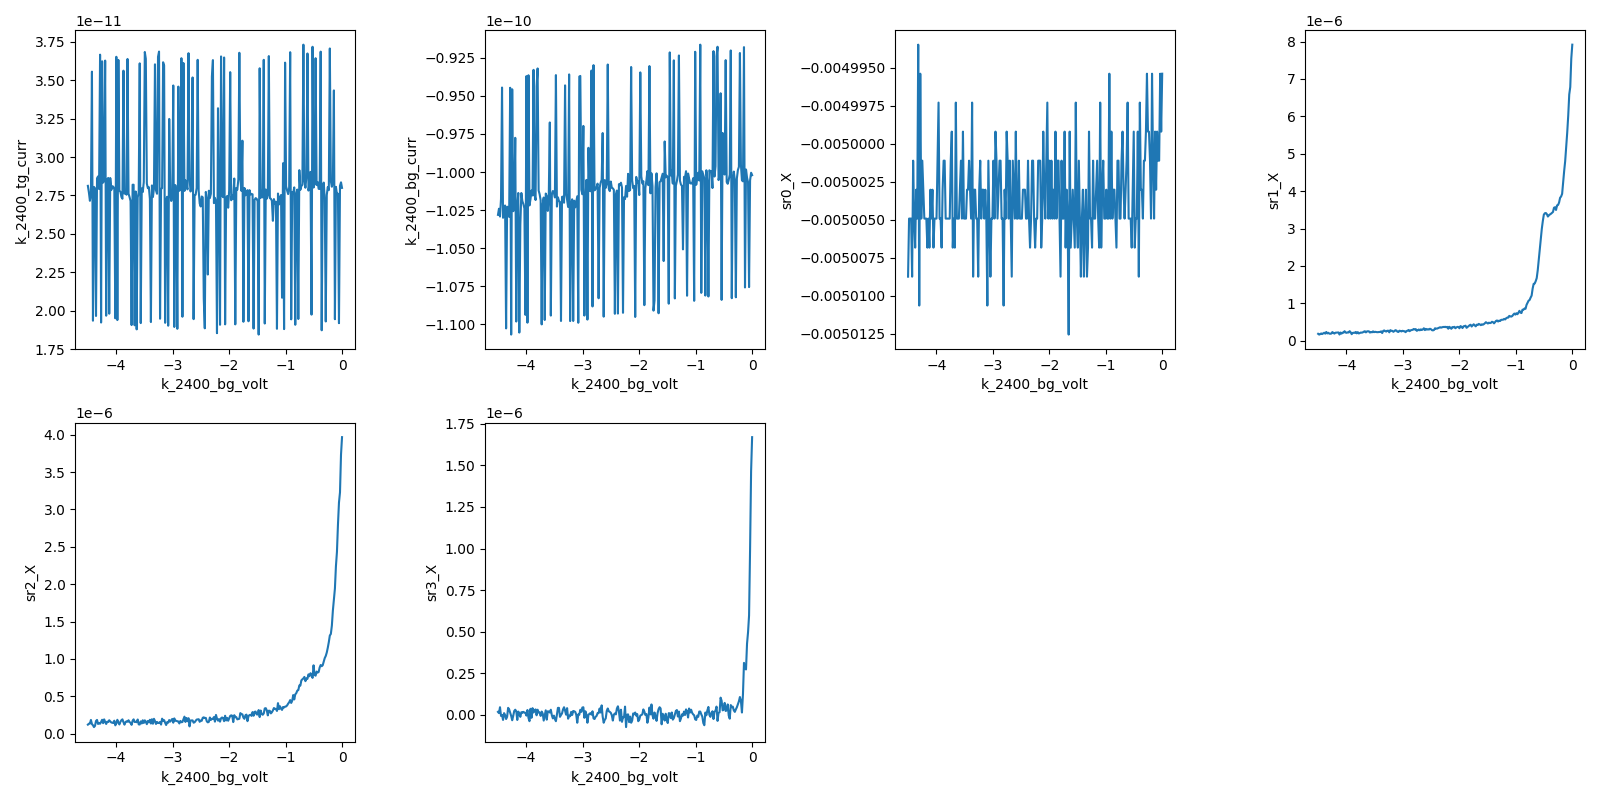

2026-07-16 15:37:48,143 [INFO] Completed in 0h 8m 58s


2026-07-16 15:37:48,143 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\3\data.tsv.gz


2026-07-16 15:37:48,663 [INFO] Ramping k_2400_bg_volt: -4.5 -> 0


In [21]:
# --- Gate C leg 4/4: k_bg 0 -> -4.5 V (card limit) --- slug: gate-current-sanity-check
# preconditions (state this cell assumes but does not set)
B, Ts = magnet.field(), T_sample()
print(f"pre: B={B:+.4f} T (expect ~0) | T={Ts:.3f} K (expect 1.0-1.5)")
assert abs(B) < 0.02 and 1.0 < Ts < 1.5, "precondition mismatch — stop"
print(f"pre: TG={k_tg.volt():+.4f} BG={k_bg.volt():+.4f} Si={k_si():+.4f} V (expect all ~0)")
assert abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01 and abs(k_si()) < 0.01

# drive per device card: 0.5 V / 100 MOhm = 5 nA at ~13 Hz (sr1 = drive lock-in)
if abs(sr1.amplitude() - 0.5) > 1e-3:
    sr1.amplitude(0.5)
if not (11 < sr1.frequency() < 15):
    sr1.frequency(13)
print(f"drive: sr1 amp {sr1.amplitude()} V, freq {sr1.frequency():.3f} Hz")

k_tg.nplci(10); k_bg.nplci(10)  # pA-floor gate-current readback; reset cell restores 1

mc = dict(meas_config)
mc["comments"] = "gate C liveness leg 4/4: k_bg 0 -> -4.5 V, other gates 0, B=0, T~1.17 K"
s = sweep.AsyncStation(mc)
s.add_comment('gate-current-sanity-check')
s.add_comment('gate: k_bg; leg: 0 -> -4.5 V (card limit); drive 5 nA @ 13 Hz')
s.ramp(k_tg.volt, 0); s.ramp(k_bg.volt, 0)
s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr).fp(k_bg.volt).fp(k_bg.curr)
s.plot(k_bg.volt, k_tg.curr)
s.plot(k_bg.volt, k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_bg.volt, lia.X)
try:
    s.sweep(k_bg.volt, np.linspace(0, BG_MIN, 251), delay=1)
finally:
    s.ramp(k_bg.volt, 0)


In [22]:
# --- Gate C close-out: reset gate-current nplci (run only if all four legs clean) ---
k_tg.nplci(1); k_bg.nplci(1)
print("k_tg.volt validator:", k_tg.volt.vals)
print("k_bg.volt validator:", k_bg.volt.vals)
print("gates parked:", k_tg.volt(), k_bg.volt(), k_si())


k_tg.volt validator: <Numbers -3.0<=v<=3.0>
k_bg.volt validator: <Numbers -4.5<=v<=4.5>
gates parked: 0.0 0.0 0.0


### Gate C — executing leg 1/4 (TG 0 → +3.0 V)

In [17]:
print('HERA: executing gate C leg 1/4 (cell 1c49ddf1) — see leg cell above for the run')

HERA: executing gate C leg 1/4 (cell 1c49ddf1) — see leg cell above for the run


## HERA — 0 T gate map, coarse-BG (CNP-line calibration) — `gatemap`

Investigation step 1 (`trilayer-stacking-fs-count`) via `device-init/cnp-and-dline-calibration`: fit the CNP ridge in (V_tg, V_bg) → c_bg/c_tg from the slope, n_offset from the intercept. Gate C found the CNP near the origin at BG = 0 (runs 0–1: sr1 peak ≈ 1.6 kΩ at V_tg ≈ 0) plus a shoulder at V_tg ≈ +0.55 V to track on the map.

**Coverage trade (stated):** geometry prior slope −c_bg/c_tg ≈ −1.3 (15.6/12 nm hBN) puts the ridge outside the TG window for |V_bg| ≳ 2.3 V, and the D = 0 line exits the validator box there too — so BG spans **±2.4 V**, not the full ±4.5: the excluded range cannot contribute unclipped ridge rows. BG rows are **coarse (25 rows, 0.2 V)** — sized for a robust linear ridge fit (~20+ surviving rows), not for feature-hunting; the price of a full 201×201 canonical map at the card's 1.2 s dwell floor is ~17 h, deferred unless this fit is inadequate (curvature / cross-channel disagreement / mosaic → escalate to a denser map over the disputed window). High-|n| clean-region ID along D = 0 comes next from a designed D = 0 line cut, which this calibration enables.

**Design:** TG fast, −3 → +3 V, 151 pts (40 mV; ridge width ~0.5 V from gate C — well resolved); BG slow −2.4 → +2.4 V, 25 rows; `fast_delay=1.2` (4τ card floor, τ = 0.3 s), `slow_delay=3`. sr1/sr2 sensitivity raised 2e-5 → **2e-4** for this map (ridge at finite D can exceed the 4 kΩ ceiling of 2e-5 at 5 nA; 2e-4 → 40 kΩ ceiling, ~1 Ω quantization keeps the metallic corners readable). Drive 5 nA @ 13 Hz unchanged.

**Wall-clock:** per-point ≈ 1.2 + 0.25 s reads (NPLC 1; reads calibrated from gate C runs 0–3: 2.2 s/pt − 1.0 delay − ~1.1 NPLC-10 Keithley term) ≈ 1.45 s → 151 × 1.45 + 7 s flyback + 3 s ≈ 230 s/row × 25 ≈ **1.6 h; realistic 1.7–1.9 h** (session actuals run over estimates). ETA stamped at launch.

**Checkpoints:** first rows (leakage, railing, dead channel — kill inside minute one) then per-row digests via the armed watch; ridge should march linearly across TG with BG. Abort call: leakage > 1 nA, a channel flat across a full row, or ridge clipped in most rows.


pre: B=+0.0033 T (expect ~0) | T=1.165 K (expect 1.0-1.5)
pre: TG=+0.0000 BG=+0.0000 Si=+0.0000 V (expect ~0)
pre: nplci TG=1.0 BG=1.0 (expect 1 — reset cell ran)
drive: sr1 amp 0.5 V, freq 13.142 Hz (expect 0.5 V / ~13 Hz)


sens: sr1 0.0002, sr2 0.0002, sr3 5e-05, sr0 0.05
2026-07-16 15:40:37,274 [INFO] Ramping k_2400_tg_volt: 0.0 -> -3.0


2026-07-16 15:40:41,171 [INFO] Ramping k_2400_bg_volt: 0.0 -> -2.4


2026-07-16 15:40:54,237 [INFO] Starting megasweep with ID 4


2026-07-16 15:40:54,238 [INFO] Minimum duration 1h 16m 45s


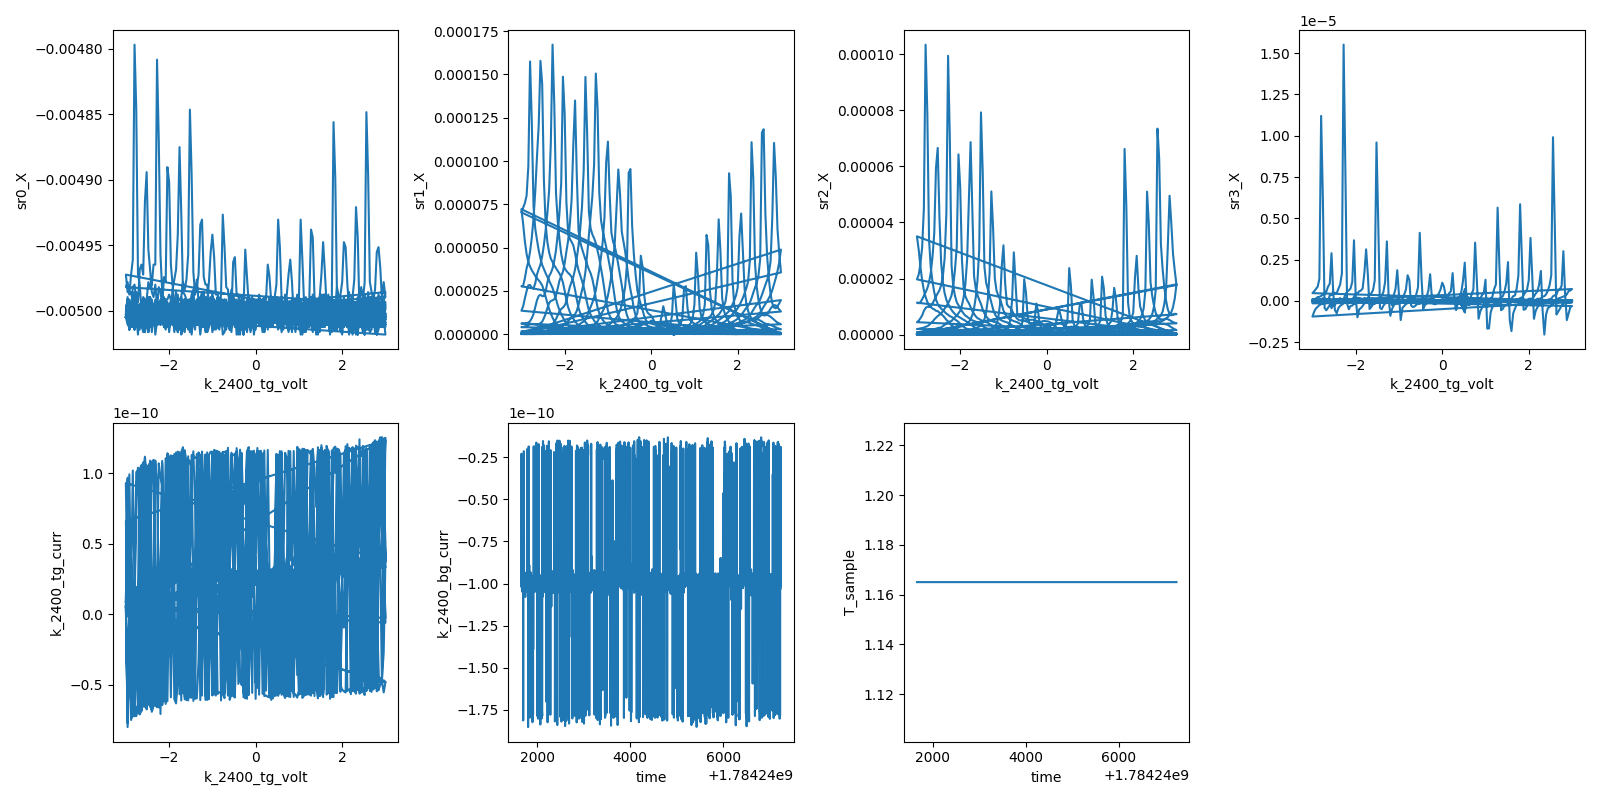

2026-07-16 17:14:04,855 [INFO] Completed in 1h 33m 9s


2026-07-16 17:14:04,856 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\4\data.tsv.gz


2026-07-16 17:14:04,925 [INFO] Ramping k_2400_tg_volt: 3.0 -> 0


2026-07-16 17:14:08,759 [INFO] Ramping k_2400_bg_volt: 2.4 -> 0


In [23]:
# --- 0 T coarse-BG gate map: TG fast [-3,+3]x151, BG slow [-2.4,+2.4]x25 --- slug: gatemap
# preconditions (assumed, not set): B~0, base T, gates parked, NPLC reset to 1
B, Ts = magnet.field(), T_sample()
print(f"pre: B={B:+.4f} T (expect ~0) | T={Ts:.3f} K (expect 1.0-1.5)")
assert abs(B) < 0.02 and 1.0 < Ts < 1.5, "precondition mismatch — stop"
print(f"pre: TG={k_tg.volt():+.4f} BG={k_bg.volt():+.4f} Si={k_si():+.4f} V (expect ~0)")
assert abs(k_si()) < 0.01, "Si gate not at 0"
npl_tg, npl_bg = k_tg.nplci(), k_bg.nplci()
print(f"pre: nplci TG={npl_tg} BG={npl_bg} (expect 1 — reset cell ran)")
assert npl_tg == 1 and npl_bg == 1, "nplci not reset — run the gate C reset cell first"
print(f"drive: sr1 amp {sr1.amplitude()} V, freq {sr1.frequency():.3f} Hz (expect 0.5 V / ~13 Hz)")
assert abs(sr1.amplitude() - 0.5) < 1e-3

# sensitivity for kΩ-scale ridge at finite D (see markdown): 40 kΩ ceiling at 5 nA
sr1.sensitivity(2e-4)
sr2.sensitivity(2e-4)
print(f"sens: sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}, sr0 {sr0.sensitivity()}")

mc = dict(meas_config)
mc["comments"] = ("0T coarse-BG gatemap for CNP-line calibration: TG fast -3->+3 (151), "
                  "BG slow -2.4->+2.4 (25), Si=0, B=0, T~1.17K, 5nA@13Hz, sr1/sr2 sens 2e-4")
s = sweep.AsyncStation(mc)
s.add_comment('gatemap')
s.add_comment('coarse-BG CNP-calibration map; feeds cnp-and-dline-calibration')
s.ramp(k_tg.volt, -3.0)
s.ramp(k_bg.volt, -2.4)
interruptible_sleep(10)

s.fp(T_sample)
s.fp(k_tg.volt).fp(k_tg.curr).fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)
s.plot(k_tg.volt, k_tg.curr)
s.plot('time', k_bg.curr)
s.plot('time', T_sample)

try:
    # megasweep(slow, slow_v, fast, fast_v) — BG slow (25 rows), TG fast (151 pts)
    s.megasweep(k_bg.volt, spoints(-2.4, 2.4, 25),
                k_tg.volt, spoints(-3.0, 3.0, 151),
                slow_delay=3, fast_delay=1.2)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — D = 0 designed-line cut, B = 0 (`cnp-and-dline-calibration` step-4 confirmation)

Confirmation cut along the freshly calibrated D = 0 line (device card, run-4 contract): paired (V_tg, V_bg) `multisweep` from n = −6e12 → +6e12 cm⁻² (241 pts, 0.05e12 step), B = 0, Si = 0. Three jobs: (1) roundtrip/on-device verification that the designed line behaves (single CNP crossing at n ≈ 0, no off-line features); (2) **R(n) anchor per channel** at the spot-check densities (sets spot-check/fan sensitivities and the MR dynamic-range budget); (3) metallicity check that all contact arms stay conducting across the full |n| range at D = 0 (investigation step-1 clean-region requirement).

Line endpoints (V_tg, V_bg): (−2.811, −2.190) → (+2.834, +2.208) — inside validators. Dwell 1.2 s (4τ floor — this data anchors quantitative reads). sr1/sr2 sens stay 2e-4.

**Wall-clock**: 241 × ~1.45 s ≈ 6 min + ramps. Cheap; single checkpoint at completion.


pre: B=+0.0033 T (expect ~0) | T=1.165 K
drive: sr1 amp 0.5 V @ 13.14 Hz; sens sr1 0.0002, sr2 0.0002
line: 241 pts, V_tg [-2.812,+2.834], V_bg [-2.190,+2.207]
2026-07-16 17:17:19,314 [INFO] Ramping k_2400_tg_volt: 0.0 -> -2.8115157010148937


2026-07-16 17:17:22,977 [INFO] Ramping k_2400_bg_volt: 0.0 -> -2.1898245198340165


2026-07-16 17:17:35,773 [INFO] Starting multisweep with ID 5


2026-07-16 17:17:35,774 [INFO] Minimum duration 0h 4m 49s


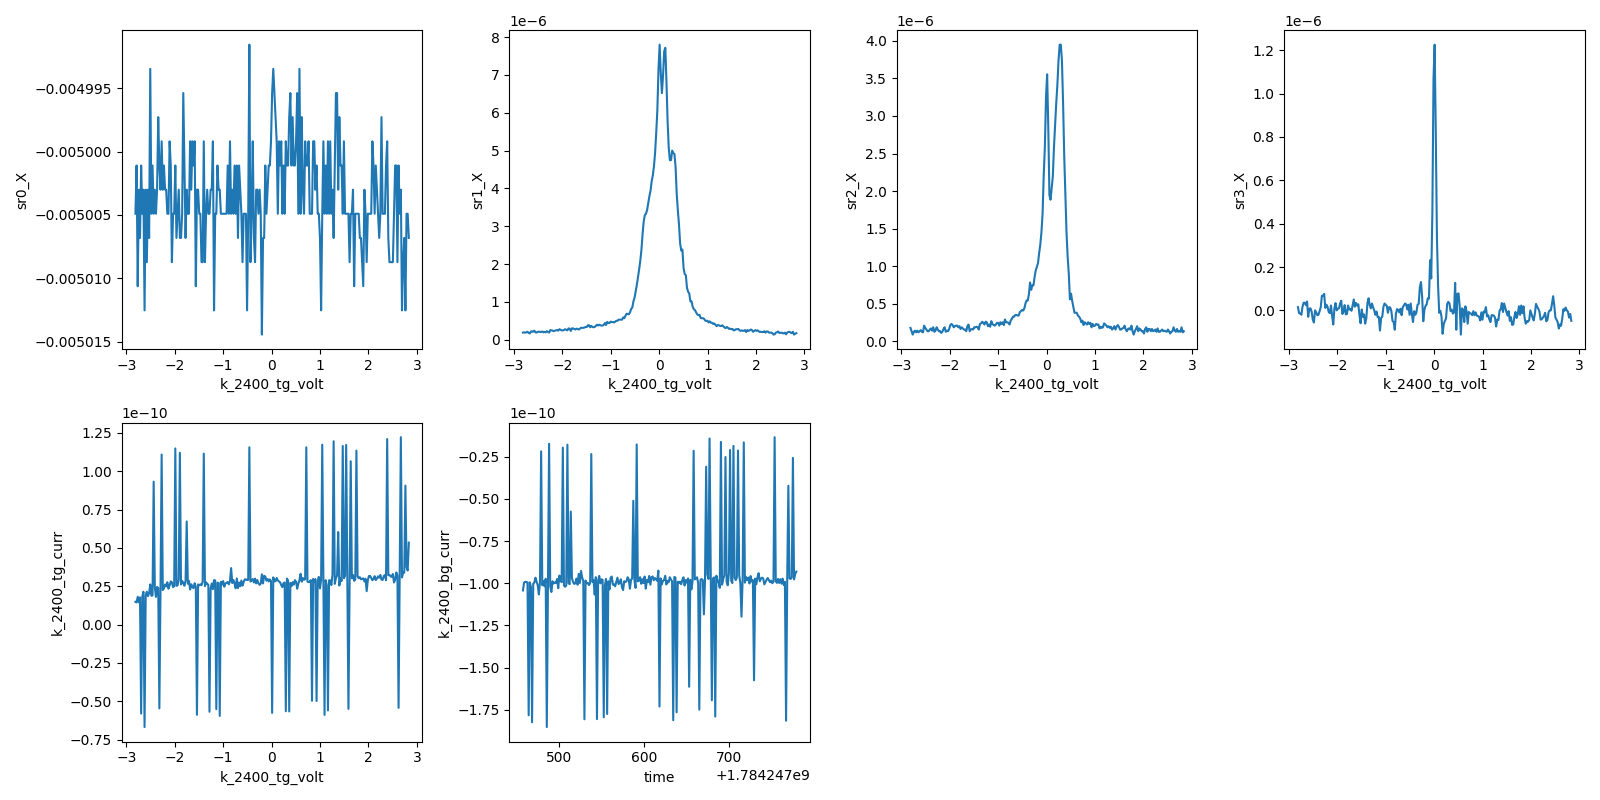

2026-07-16 17:23:00,580 [INFO] Completed in 0h 5m 24s


2026-07-16 17:23:00,581 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\5\data.tsv.gz


2026-07-16 17:23:00,644 [INFO] Ramping k_2400_tg_volt: 2.834 -> 0


2026-07-16 17:23:04,269 [INFO] Ramping k_2400_bg_volt: 2.2075 -> 0


In [24]:
# --- D=0 line cut: n -6e12 -> +6e12 (241 pts), B=0 --- slug: cnp-and-dline-calibration
import scipy.constants as cst

# preconditions
B, Ts = magnet.field(), T_sample()
print(f"pre: B={B:+.4f} T (expect ~0) | T={Ts:.3f} K")
assert abs(B) < 0.02 and 1.0 < Ts < 1.5
assert abs(k_si()) < 0.01, "Si gate not at 0"
print(f"drive: sr1 amp {sr1.amplitude()} V @ {sr1.frequency():.2f} Hz; sens sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}")

# run-4 calibration (device card contract): ratio data-calibrated, scale geometry prior
C_TG = cst.epsilon_0 * 3.0 / 15.6e-9
RATIO = 1.2839
N_OFFSET = -2.407e14  # m^-2
ns = np.linspace(-6e16, 6e16, 241)          # m^-2
Vbgs = (ns - N_OFFSET) * cst.e / (2 * C_TG * RATIO)
Vtgs = RATIO * Vbgs
Vtgs, Vbgs = sanitize_tg_bg(Vtgs, Vbgs, tg_lims, bg_lims)
print(f"line: {len(Vtgs)} pts, V_tg [{Vtgs.min():+.3f},{Vtgs.max():+.3f}], V_bg [{Vbgs.min():+.3f},{Vbgs.max():+.3f}]")

mc = dict(meas_config)
mc["comments"] = "D=0 designed-line cut, n -6e12->+6e12 (241 pts), B=0, T~1.17K; run-4 calibration confirmation"
s = sweep.AsyncStation(mc)
s.add_comment('cnp-and-dline-calibration')
s.add_comment('D=0 line cut; c_bg/c_tg=1.2839, n_offset=-2.407e14 m^-2 (run 4)')
s.ramp(k_tg.volt, Vtgs[0]); s.ramp(k_bg.volt, Vbgs[0])
interruptible_sleep(10)
s.fp(T_sample)
s.fp(k_tg.curr).fp(k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)
s.plot(k_tg.volt, k_tg.curr)
s.plot('time', k_bg.curr)
try:
    s.multisweep([k_tg.volt, k_bg.volt], [Vtgs, Vbgs], delay=1.2)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — SdH spot check 1/2: hole side, n = −6e12, D = 0 (`sdh-spot-check`)

Investigation step 3. Fixed-(n, D) field sweep, **uniform in B** (blocking rate-limited magnet branch): ΔB = Δ(1/B)·B_lo² with Δ(1/B) = 1/(3·F_L) at F_L = (h/4e)·6e12 = **62.0 T** → ΔB = 5.38 mT at B_lo = 1.0 T → **1303 pts, 1 → 8 T**. B_lo = 1.0 T sits below the expected onset (T_e ≈ 8 K on this rig pushes onset well above the ~0.1 T heuristic; ħω_c ≳ kT already at ~0.3 T, so quantum lifetime — not thermal smearing — will set it); the onset is *measured* here, not assumed. δF = 1/(1/B_onset − 1/8): 1.14 T if onset 1 T, 1.85 T if 1.5 T — the ABA partition (f_ML expected several T at this n) resolves if onset ≲ 1.5–2 T.

**Gates**: (V_tg, V_bg) = (−2.8115, −2.1898) — run-4 calibration, D = 0. **Drive**: card high-|n| standard 2 V → 20 nA @ 13 Hz. **Sens**: sr1/sr2 5e-5 (2.5 kΩ ceiling at 20 nA = ×70 MR headroom over the 35 Ω anchor from run 5; B = 0 signal ~1.4% FS — grainy only below onset, outside the FFT window; clipping at high B is the unrecoverable failure, so headroom wins), sr3 5e-5 (Rxy ≈ 833 Ω at 8 T), sr0 unchanged. **Dwell**: `magnet.settle_s` 3 → **1.2 s** for this sweep (= 4τ; the lock-in tracks through the blocking ramp, each step 5.4 mT ≈ 2.4 s of ramp; documented tunable, restored in `finally`).

**Magnet plan**: position 0 → 1 T (~7 min), sweep up to 8 T; **ends at 8 T** — spot check 2 (electron side) rides 8 → 0 down. No re-traverse.

**Wall-clock**: 1303 × (2.35 ramp + 1.2 settle + ~0.35 reads) ≈ 85 min + 7 min positioning ≈ **1.6 h, realistic 1.7–1.8 h**.

**Checkpoints**: first rows (MR shape, no clip, drain steady), then ~mid-sweep (any visible QO above the noise; sens headroom vs MR trend). Abort: railed channel, drain sag, leakage.


pre: B=+0.0033 T (expect ~0) | T=1.165 K


drive 2.0 V @ 13.14 Hz -> I_bias 20 nA; sens sr1 5e-05, sr2 5e-05, sr3 5e-05, sr0 0.05
magnet.settle_s: 3.0 -> 1.2
2026-07-16 17:25:53,773 [INFO] Ramping k_2400_tg_volt: 0.0 -> -2.8115


2026-07-16 17:25:57,411 [INFO] Ramping k_2400_bg_volt: 0.0 -> -2.1898


2026-07-16 17:26:10,204 [INFO] Ramping magnet_field: 0.0033501369863013697 -> 1.0


2026-07-16 17:33:28,889 [INFO] Starting sweep with ID 6


2026-07-16 17:33:28,890 [INFO] Minimum duration 0h 0m 0s


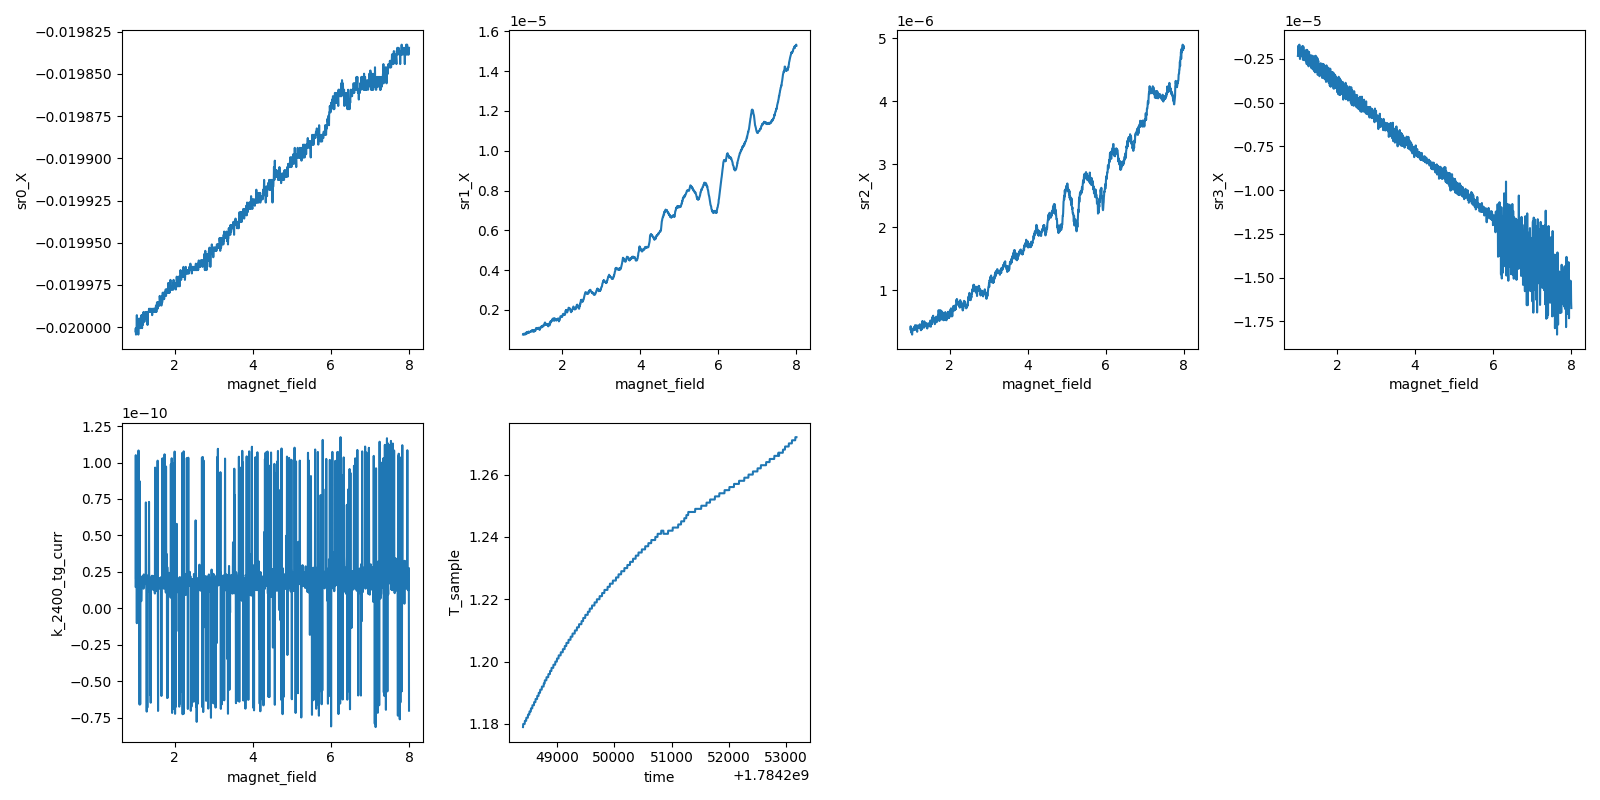

2026-07-16 18:52:59,106 [INFO] Completed in 1h 19m 29s


2026-07-16 18:52:59,106 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\6\data.tsv.gz


end: B=+8.004 T (left for SC2 ride-down), gates parked, settle_s=3.0


In [25]:
# --- SdH spot check 1/2: hole side n=-6e12, D=0, B 1->8 T uniform-B --- slug: sdh-spot-check
B0, Ts = magnet.field(), T_sample()
print(f"pre: B={B0:+.4f} T (expect ~0) | T={Ts:.3f} K")
assert abs(B0) < 0.05 and 1.0 < Ts < 1.5, "precondition mismatch"
assert abs(k_si()) < 0.01, "Si gate not at 0"

# drive: card high-|n| standard 2 V -> 20 nA; sens with MR headroom (see markdown)
sr1.amplitude(2.0)
sr1.sensitivity(5e-5); sr2.sensitivity(5e-5); sr3.sensitivity(5e-5)
print(f"drive {sr1.amplitude()} V @ {sr1.frequency():.2f} Hz -> I_bias 20 nA; "
      f"sens sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}, sr0 {sr0.sensitivity()}")

VTG, VBG = -2.8115, -2.1898   # n=-6e12, D=0 (run-4 calibration)
B_vec = np.linspace(1.0, 8.0, 1303)   # dB = 5.38 mT = (1/3F_L)*B_lo^2, F_L=62 T

settle_saved = magnet.settle_s
magnet.settle_s = 1.2   # = 4*tau dwell per point (lock-in tracks through the ramp)
print(f"magnet.settle_s: {settle_saved} -> {magnet.settle_s}")

mc = dict(meas_config)
mc["comments"] = ("SdH spot check hole side: n=-6e12 cm^-2, D=0 (Vtg -2.8115, Vbg -2.1898), "
                  "B 1->8 T, 1303 pts dB=5.38mT, 20nA@13Hz, T~1.17K")
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment('hole side; F_L=62.0 T; d(1/B)=5.38e-3/T (1/3 Nyquist); ends at 8 T for SC2 ride-down')
s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG)
interruptible_sleep(10)
s.fp(T_sample)
s.fp(k_tg.curr).fp(k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)
s.plot(magnet.field, k_tg.curr)
s.plot('time', T_sample)

try:
    s.ramp(magnet.field, 1.0)   # blocking position ramp, ~7 min
    s.sweep(magnet.field, B_vec, delay=0)   # dwell = settle_s per point
finally:
    magnet.settle_s = settle_saved
    k_tg.volt(0); k_bg.volt(0)
    print(f"end: B={magnet.field():+.3f} T (left for SC2 ride-down), gates parked, settle_s={magnet.settle_s}")


## HERA — SdH spot check 2/2: electron side, n = +6e12, D = 0 (`sdh-spot-check`)

Mirror of SC1 on the electron side, riding the magnet **down 8 → 1 T** from where SC1 left it (no re-traverse). Same design: F_L(nominal) = 62.0 T, ΔB = 5.38 mT uniform-B (Nyquist held at the 1 T end), 1303 pts descending; gates (V_tg, V_bg) = (+2.8342, +2.2075) — run-4 calibration, D = 0. Drive 20 nA @ 13 Hz, sens sr1/sr2/sr3 5e-5, `magnet.settle_s` 1.2 (restored after). SC1 interim already shows the {12, 55, 67≈sum} T set on the hole side; SC2 asks (a) does the electron side show the matching combinatorics, (b) which side is cleaner for the fan (investigation step 3 decision).

**Ends at 1 T** — the fan (step 4) starts near the measured onset, so the magnet parks exactly where the next measurement needs it.

**Wall-clock**: 1303 × ~3.7 s ≈ 80 min (SC1-calibrated rate; no positioning ramp needed).

**Checkpoints**: first rows (drain/clip/Hall sign flip), mid-run FFT. Abort on rail/sag/leakage.


pre: B=+8.003 T (expect ~8, SC1 endpoint) | T=1.272 K
drive 2.0 V @ 13.14 Hz (expect 2 V); sens sr1 5e-05, sr2 5e-05, sr3 5e-05


2026-07-16 18:56:27,116 [INFO] Ramping k_2400_tg_volt: 0.0 -> 2.8342


2026-07-16 18:56:30,738 [INFO] Ramping k_2400_bg_volt: 0.0 -> 2.2075


2026-07-16 18:56:43,494 [INFO] Starting sweep with ID 7


2026-07-16 18:56:43,495 [INFO] Minimum duration 0h 0m 0s


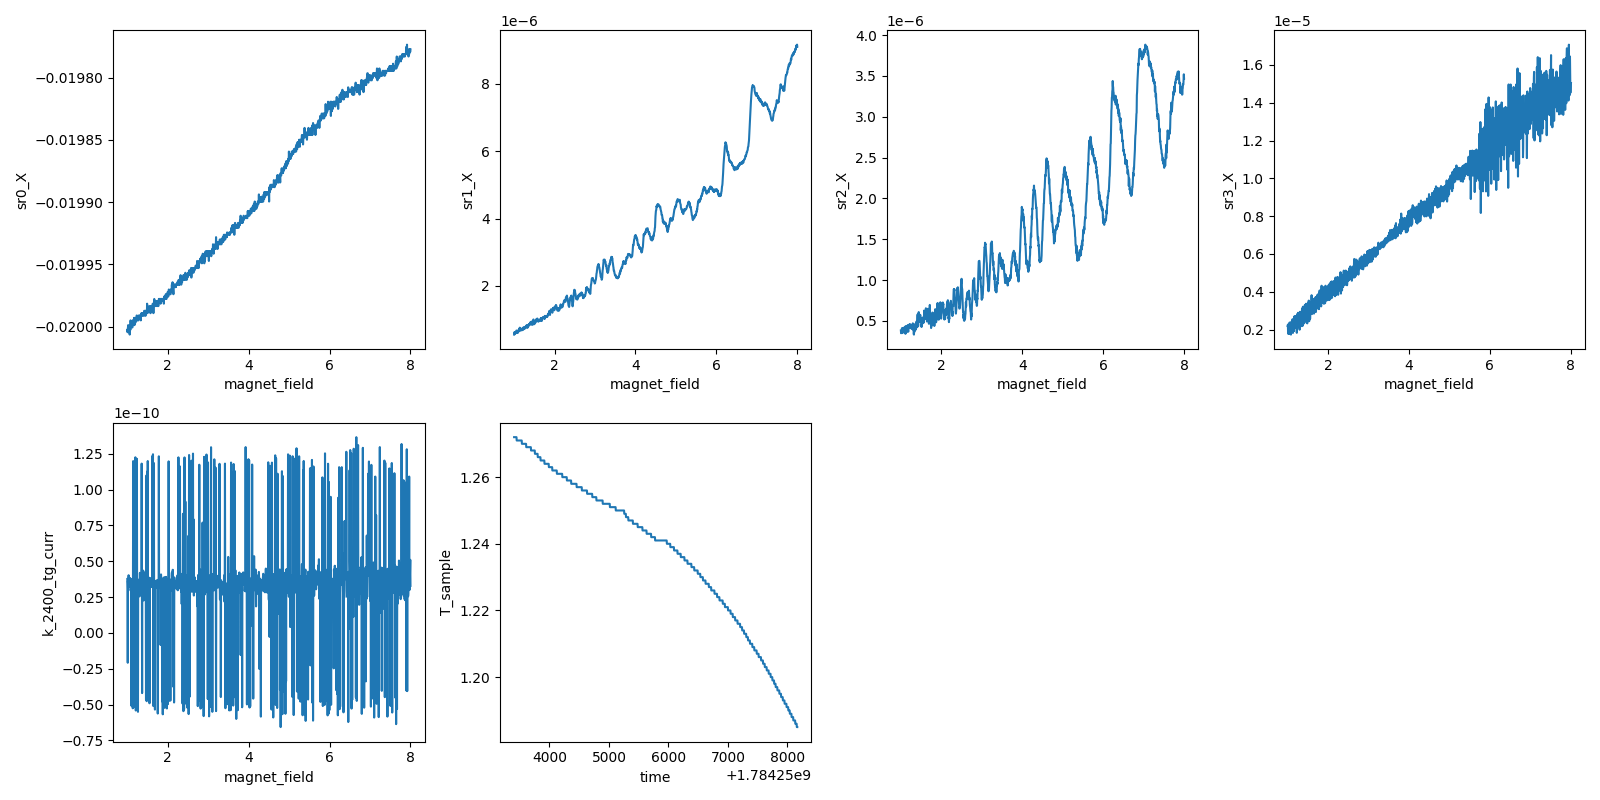

2026-07-16 20:16:06,861 [INFO] Completed in 1h 19m 22s


2026-07-16 20:16:06,861 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\7\data.tsv.gz


end: B=+1.002 T (fan starts near here), gates parked, settle_s=3.0


In [26]:
# --- SdH spot check 2/2: electron side n=+6e12, D=0, B 8->1 T uniform-B --- slug: sdh-spot-check
B0, Ts = magnet.field(), T_sample()
print(f"pre: B={B0:+.3f} T (expect ~8, SC1 endpoint) | T={Ts:.3f} K")
assert 7.9 < B0 < 8.05 and 1.0 < Ts < 1.5, "precondition mismatch"
assert abs(k_si()) < 0.01, "Si gate not at 0"
assert abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01, "gates not parked"
print(f"drive {sr1.amplitude()} V @ {sr1.frequency():.2f} Hz (expect 2 V); "
      f"sens sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}")
assert abs(sr1.amplitude() - 2.0) < 1e-2

VTG, VBG = +2.8342, +2.2075   # n=+6e12, D=0 (run-4 calibration)
B_vec = np.linspace(8.0, 1.0, 1303)   # descending; dB = 5.38 mT

settle_saved = magnet.settle_s
magnet.settle_s = 1.2
mc = dict(meas_config)
mc["comments"] = ("SdH spot check electron side: n=+6e12 cm^-2, D=0 (Vtg +2.8342, Vbg +2.2075), "
                  "B 8->1 T descending, 1303 pts dB=5.38mT, 20nA@13Hz, T~1.17K")
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment('electron side; F_L=62.0 T nominal; rides SC1 endpoint 8 T down to 1 T for the fan')
s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG)
interruptible_sleep(10)
s.fp(T_sample)
s.fp(k_tg.curr).fp(k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)
s.plot(magnet.field, k_tg.curr)
s.plot('time', T_sample)

try:
    s.sweep(magnet.field, B_vec, delay=0)
finally:
    magnet.settle_s = settle_saved
    k_tg.volt(0); k_bg.volt(0)
    print(f"end: B={magnet.field():+.3f} T (fan starts near here), gates parked, settle_s={magnet.settle_s}")


## HERA — Landau fan, hole side, D = 0 (`landau-fan-vti`)

Investigation step 4: the dense version of run 6. **n = −1.5 → −6.0e12** (hole side per SC verdict), D = 0 paired n-line fast axis; **B slow, uniform-1/B** (`field_invB`), 1.6 → 8 T ascending — magnet sits at 1 T (SC2 endpoint), fan starts where it is and **ends at 8 T** for a ride-down grid-change cut (Verify: alias screen).

**Design (recipe step-1 checks, stated):**
- **N_B = 101** rows, Δ(1/B) = 5.0e-3 /T = ⅓-Nyquist at the *measured* partition sum 66.4 T (tightened from the 62 T nominal). B_lo = 1.6 T: onset measured 1.41 T (run 7 sr2, `sdh_onset`) / ~1.8 T eye (run 6); 1.6 splits the band — low-B rows are the fan's cheapest (14 mT steps).
- **N_n = 87** (Δn = 0.052e12): ray-Nyquist 3.0 rows/period at the 1.6 T, n = −6e12 corner (≥2 floor, at the prefer-3 mark). δF = 1/(1/1.6 − 1/8) = 2.0 T → partition claims trusted for |n| ≳ 2.5e12 (f_ML ≥ 2·δF); low-n columns are shape/onset data, stated floor.
- **Overlay validity**: Onsager model clamp |n| ≤ 3.5e12 — overlay runs on that sub-window only; the Luttinger partition check (algebraic) uses the full window.
- **Dynamic range (worst corner −1.5e12 × 8 T, R₀ = 127 Ω × MR ~×20–30 ≈ 2.5–3.8 kΩ)**: split sensitivities — **sr1 2e-4** (10 kΩ, no-clip channel, owns low-|n| columns), **sr2 5e-5** (fine digitization, owns high-|n| columns; its low-n × high-B corner will clip → excluded from sr2 reads), **sr3 2e-4** (Rxy → 3.3 kΩ at corner). Every corner has one clean channel.
- **Dwell**: fast_delay = 1.8 s (6τ — n-axis feeds per-column FFT, recipe step 7); slow_delay = 1; `magnet.settle_s` 1.2 for the fan (restored after).

**Wall-clock**: 101 × (87 × ~2.05 s + ~5 s turnaround) ≈ 5.1 h + B traverse 6.4 T ≈ 47 min + positioning ≈ **6.0 h; realistic 6.3–6.6 h** (session-calibrated rates: 3.7 s/pt SC runs, 1.45 s/pt gate sweeps). Overnight run, ETA ~03:00.

**Checkpoints**: first rows (clip/drain/leakage), then every ~90 min: re-formed partial fan + per-column FFT on landed rows — continue/abort on: sensitivity railing beyond plan, drain sag, T excursion, or frequency content collapsing (acquisition fault). Ends parked: gates 0, B = 8 T.


pre: B=+1.003 T (expect ~1, SC2 endpoint) | T=1.184 K


sens: sr1 0.0002, sr2 5e-05, sr3 0.0002, sr0 0.05
n-line: 87 pts, Vtg [-2.812,-0.694], Vbg [-2.190,-0.541]
B rows: 101, 1.600 -> 8.000 T; dB 0.0129 .. 0.3077 T
2026-07-16 20:19:35,460 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.6943857054214009


2026-07-16 20:19:36,405 [INFO] Ramping k_2400_bg_volt: 0.0 -> -0.5408409575678798


2026-07-16 20:19:47,098 [INFO] Starting multimegasweep with ID 8


2026-07-16 20:19:47,099 [INFO] Minimum duration 4h 25m 17s


2026-07-16 20:31:29,123 [WARNING] ID 8 INTERRUPTED


2026-07-16 20:31:29,124 [WARNING] ID 8 INTERRUPTED


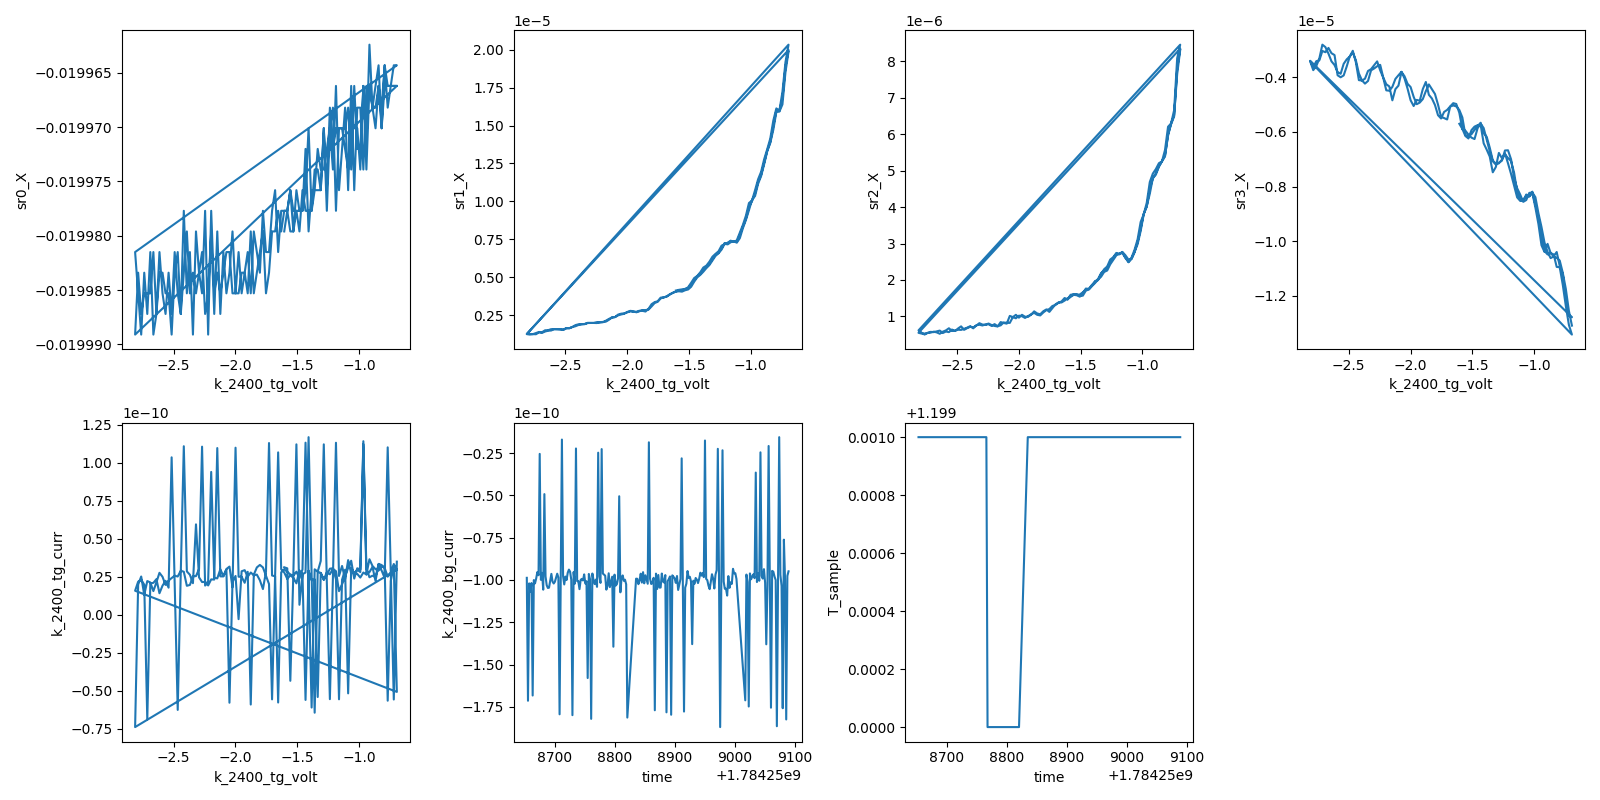

2026-07-16 20:31:29,825 [INFO] Completed in 0h 11m 42s


2026-07-16 20:31:29,826 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\8\data.tsv.gz


end: B=+1.629 T, gates parked, settle_s=3.0


In [27]:
# --- Landau fan hole side: B 1.6->8 T uniform-1/B x101, n -1.5->-6e12 x87, D=0 --- slug: landau-fan-vti
import scipy.constants as cst

B0, Ts = magnet.field(), T_sample()
print(f"pre: B={B0:+.3f} T (expect ~1, SC2 endpoint) | T={Ts:.3f} K")
assert 0.9 < B0 < 1.7 and 1.0 < Ts < 1.5, "precondition mismatch"
assert abs(k_si()) < 0.01 and abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01
assert abs(sr1.amplitude() - 2.0) < 1e-2, "drive not at 2 V (20 nA)"

# split sensitivities (see markdown): sr1 no-clip, sr2 fine-digitization, sr3 Hall range
sr1.sensitivity(2e-4); sr2.sensitivity(5e-5); sr3.sensitivity(2e-4)
print(f"sens: sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}, sr0 {sr0.sensitivity()}")

# fast axis: D=0 paired n-line, run-4 calibration
C_TG = cst.epsilon_0 * 3.0 / 15.6e-9
RATIO, N_OFF = 1.2839, -2.407e14
ns = np.linspace(-1.5e16, -6.0e16, 87)              # m^-2
Vbgs = (ns - N_OFF) * cst.e / (2 * C_TG * RATIO)
Vtgs = RATIO * Vbgs
Vtgs, Vbgs = sanitize_tg_bg(Vtgs, Vbgs, tg_lims, bg_lims)
print(f"n-line: {len(Vtgs)} pts, Vtg [{Vtgs.min():+.3f},{Vtgs.max():+.3f}], Vbg [{Vbgs.min():+.3f},{Vbgs.max():+.3f}]")

# slow axis: uniform in 1/B, 1.6 -> 8 T ascending
B_vec = field_invB(1.6, 8.0, 101)
print(f"B rows: {len(B_vec)}, {B_vec[0]:.3f} -> {B_vec[-1]:.3f} T; dB {B_vec[1]-B_vec[0]:.4f} .. {B_vec[-1]-B_vec[-2]:.4f} T")

settle_saved = magnet.settle_s
magnet.settle_s = 1.2

mc = dict(meas_config)
mc["comments"] = ("Landau fan hole side: n -1.5->-6e12 (87 pts, D=0, run-4 cal), "
                  "B 1.6->8 T uniform-1/B (101 rows, d(1/B)=5.0e-3), 20nA@13Hz, "
                  "sens sr1 2e-4/sr2 5e-5/sr3 2e-4, fast_delay 1.8 (6tau), T~1.17K")
s = sweep.AsyncStation(mc)
s.add_comment('landau-fan-vti')
s.add_comment('D = 0, n = -1.5 to -6.0e12 cm^-2, B = 1.6 to 8 T; per-column-FFT fan; ends 8 T for ride-down grid-change cut')
s.fp(T_sample)
s.fp(k_tg.curr).fp(k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)
s.plot(k_tg.volt, k_tg.curr)
s.plot('time', k_bg.curr)
s.plot('time', T_sample)

try:
    s.ramp(k_tg.volt, Vtgs[0]); s.ramp(k_bg.volt, Vbgs[0])
    interruptible_sleep(10)
    s.multimegasweep([magnet.field], [B_vec],
                     [k_tg.volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=1, fast_delay=1.8)
finally:
    magnet.settle_s = settle_saved
    k_tg.volt(0); k_bg.volt(0)
    print(f"end: B={magnet.field():+.3f} T, gates parked, settle_s={magnet.settle_s}")


## HERA — Landau fan v2 (sr1 re-sized) — `landau-fan-vti`

Fan v1 (run 8) killed at the first-rows checkpoint, 4 min in: the low-n corner read 994 Ω already at 1.6 T (×7.8 over B = 0 — near-CNP MR is far steeper than the high-|n| ×20 the sizing used), projecting through sr1's 10 kΩ ceiling at high B — and the clipped columns would be exactly the low-n ones the f_ML claim needs. Cheapest kill is in the first minute; run 8 stands as the record of the miss.

**Only change from v1: sr1 sensitivity 2e-4 → 5e-4** (25 kΩ ceiling; worst corner now ~14 kΩ projected → ~×1.8 headroom). Digitization at the high-|n| end of sr1 degrades to ~0.1% FS — sr2 (5e-5, unchanged) owns those columns per the split-sensitivity plan. All other design numbers as v1 (101 × 87, Δ(1/B) = 5.0e-3, B 1.6 → 8 T, fast_delay 1.8). Wall-clock unchanged ~6.3–6.6 h.


pre: B=+1.629 T (expect ~1, SC2 endpoint) | T=1.200 K


sens: sr1 0.0005, sr2 5e-05, sr3 0.0002, sr0 0.05
n-line: 87 pts, Vtg [-2.812,-0.694], Vbg [-2.190,-0.541]
B rows: 101, 1.600 -> 8.000 T; dB 0.0129 .. 0.3077 T
2026-07-16 20:32:58,294 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.6943857054214009


2026-07-16 20:32:59,238 [INFO] Ramping k_2400_bg_volt: 0.0 -> -0.5408409575678798


2026-07-16 20:33:09,927 [INFO] Starting multimegasweep with ID 9


2026-07-16 20:33:09,928 [INFO] Minimum duration 4h 25m 17s


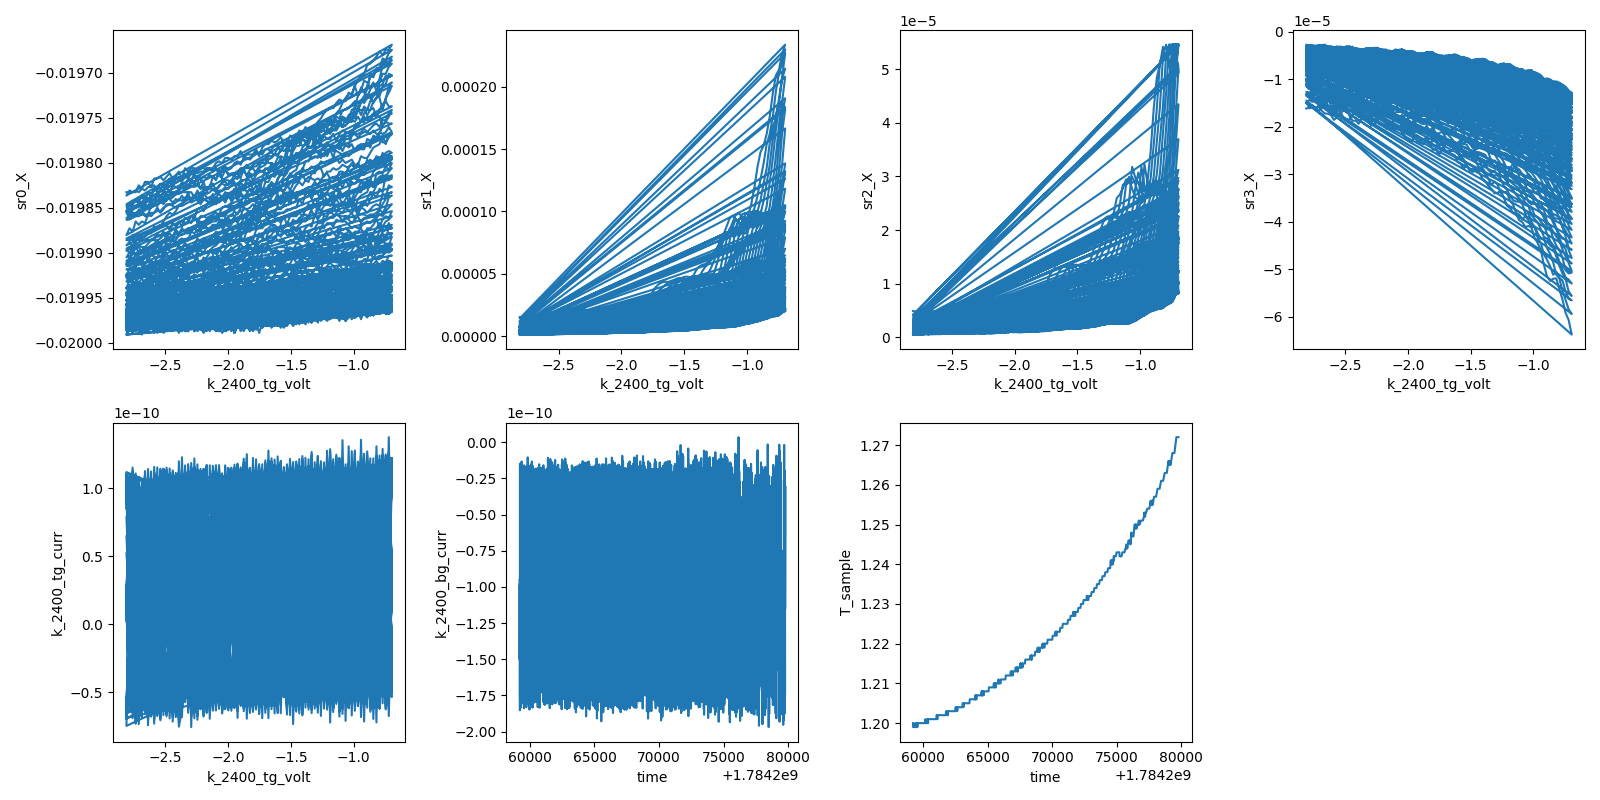

2026-07-17 02:16:15,215 [INFO] Completed in 5h 43m 4s


2026-07-17 02:16:15,217 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\9\data.tsv.gz


end: B=+8.003 T, gates parked, settle_s=3.0


In [28]:
# --- Landau fan hole side: B 1.6->8 T uniform-1/B x101, n -1.5->-6e12 x87, D=0 --- slug: landau-fan-vti
import scipy.constants as cst

B0, Ts = magnet.field(), T_sample()
print(f"pre: B={B0:+.3f} T (expect ~1, SC2 endpoint) | T={Ts:.3f} K")
assert 0.9 < B0 < 1.75 and 1.0 < Ts < 1.5, "precondition mismatch"
assert abs(k_si()) < 0.01 and abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01
assert abs(sr1.amplitude() - 2.0) < 1e-2, "drive not at 2 V (20 nA)"

# split sensitivities (see markdown): sr1 no-clip, sr2 fine-digitization, sr3 Hall range
sr1.sensitivity(5e-4); sr2.sensitivity(5e-5); sr3.sensitivity(2e-4)
print(f"sens: sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}, sr0 {sr0.sensitivity()}")

# fast axis: D=0 paired n-line, run-4 calibration
C_TG = cst.epsilon_0 * 3.0 / 15.6e-9
RATIO, N_OFF = 1.2839, -2.407e14
ns = np.linspace(-1.5e16, -6.0e16, 87)              # m^-2
Vbgs = (ns - N_OFF) * cst.e / (2 * C_TG * RATIO)
Vtgs = RATIO * Vbgs
Vtgs, Vbgs = sanitize_tg_bg(Vtgs, Vbgs, tg_lims, bg_lims)
print(f"n-line: {len(Vtgs)} pts, Vtg [{Vtgs.min():+.3f},{Vtgs.max():+.3f}], Vbg [{Vbgs.min():+.3f},{Vbgs.max():+.3f}]")

# slow axis: uniform in 1/B, 1.6 -> 8 T ascending
B_vec = field_invB(1.6, 8.0, 101)
print(f"B rows: {len(B_vec)}, {B_vec[0]:.3f} -> {B_vec[-1]:.3f} T; dB {B_vec[1]-B_vec[0]:.4f} .. {B_vec[-1]-B_vec[-2]:.4f} T")

settle_saved = magnet.settle_s
magnet.settle_s = 1.2

mc = dict(meas_config)
mc["comments"] = ("Landau fan hole side: n -1.5->-6e12 (87 pts, D=0, run-4 cal), "
                  "B 1.6->8 T uniform-1/B (101 rows, d(1/B)=5.0e-3), 20nA@13Hz, "
                  "sens sr1 2e-4/sr2 5e-5/sr3 2e-4, fast_delay 1.8 (6tau), T~1.17K")
s = sweep.AsyncStation(mc)
s.add_comment('landau-fan-vti')
s.add_comment('D = 0, n = -1.5 to -6.0e12 cm^-2, B = 1.6 to 8 T; per-column-FFT fan; ends 8 T for ride-down grid-change cut')
s.fp(T_sample)
s.fp(k_tg.curr).fp(k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, lia.X)
s.plot(k_tg.volt, k_tg.curr)
s.plot('time', k_bg.curr)
s.plot('time', T_sample)

try:
    s.ramp(k_tg.volt, Vtgs[0]); s.ramp(k_bg.volt, Vbgs[0])
    interruptible_sleep(10)
    s.multimegasweep([magnet.field], [B_vec],
                     [k_tg.volt, k_bg.volt], [Vtgs, Vbgs],
                     slow_delay=1, fast_delay=1.8)
finally:
    magnet.settle_s = settle_saved
    k_tg.volt(0); k_bg.volt(0)
    print(f"end: B={magnet.field():+.3f} T, gates parked, settle_s={magnet.settle_s}")


## HERA — ride-down SdH spot check: electron side, n = +3.0e12, D = 0 (`sdh-spot-check`)

The fan ends at 8 T; this rides the magnet down 8 → 1.3 T as a measured sweep (never re-traverse). Purpose: the session's **only model-quantitative Onsager point** — electron side (the model solves electrons only) at |n|·λ ≈ 3.15e12, inside the 3.5e12 clamp — plus a grid-independent tone set at a third density. F_L(nominal) = 31.0 T → Δ(1/B) = 1.075e-2 → ΔB = 18.2 mT at the 1.3 T end → **369 pts**. Gates from the run-4 calibration at D = 0. Sens unchanged (sr1 5e-4 / sr2 5e-5 / sr3 2e-4); drive 20 nA.

**Wall-clock**: 369 × ~9.5 s (8 s ramp/pt + 1.2 settle + reads) ≈ **1.0 h**. Ends at 1.3 T; propose parking B → 0 after the read (session wrap).


pre: B=+8.003 T (expect ~8, fan endpoint) | T=1.272 K
sens: sr1 0.0005, sr2 5e-05, sr3 0.0002
gates: VTG=+1.4227, VBG=+1.1081 (n=+3.0e12, D=0)


2026-07-17 02:18:28,564 [INFO] Ramping k_2400_tg_volt: 0.0 -> 1.422744290172092


2026-07-17 02:18:30,411 [INFO] Ramping k_2400_bg_volt: 0.0 -> 1.1081426046982568


2026-07-17 02:18:41,798 [INFO] Starting sweep with ID 10


2026-07-17 02:18:41,799 [INFO] Minimum duration 0h 0m 0s


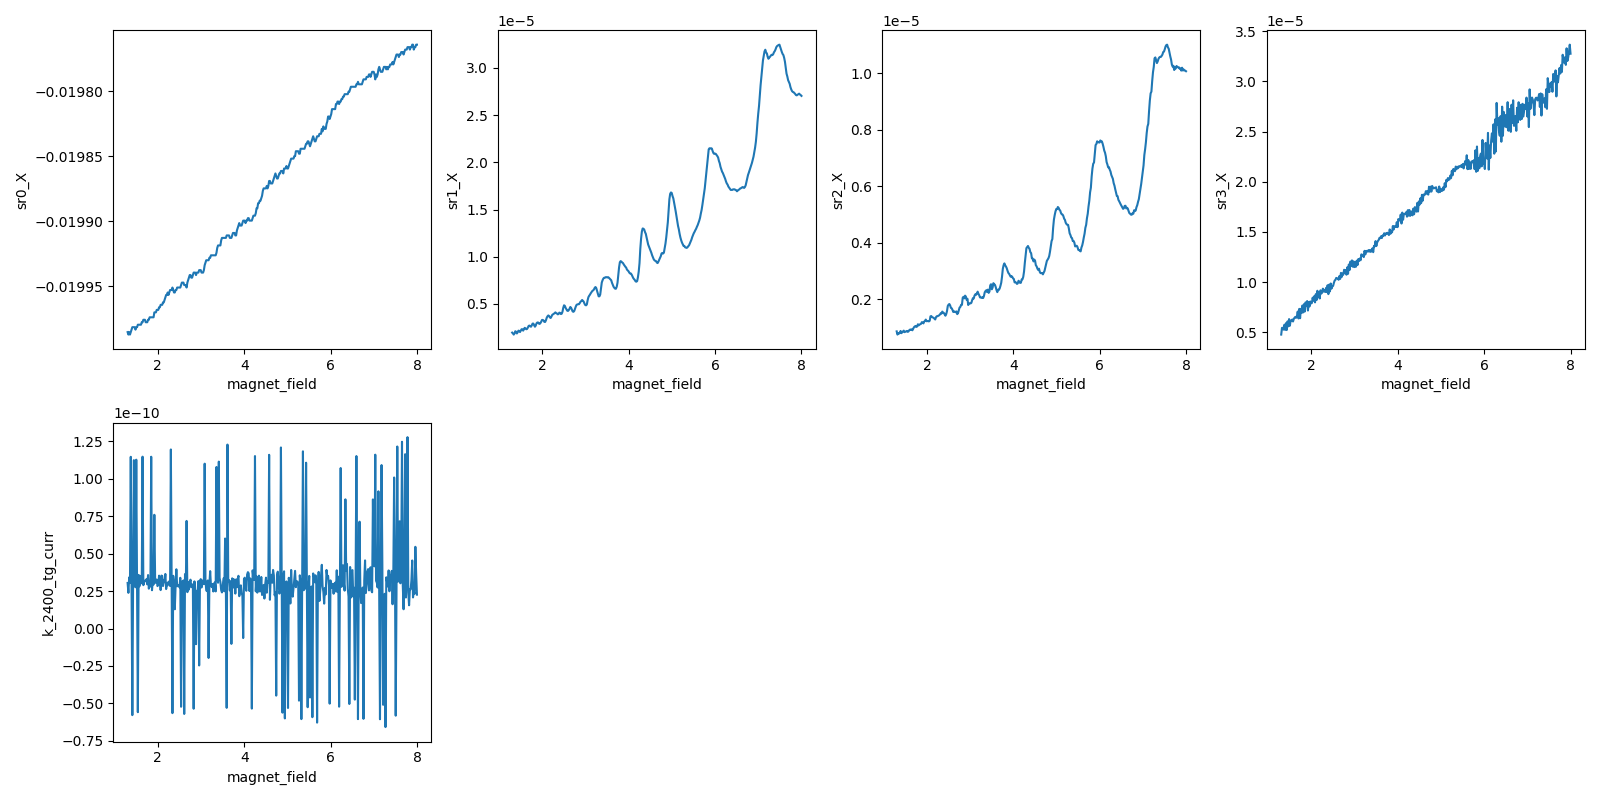

2026-07-17 03:15:31,677 [INFO] Completed in 0h 56m 49s


2026-07-17 03:15:31,678 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260716-QC0426\data\10\data.tsv.gz


end: B=+1.300 T, gates parked, settle_s=3.0


In [29]:
# --- ride-down SdH: electron n=+3.0e12, D=0, B 8->1.3 T --- slug: sdh-spot-check
import scipy.constants as cst
B0, Ts = magnet.field(), T_sample()
print(f"pre: B={B0:+.3f} T (expect ~8, fan endpoint) | T={Ts:.3f} K")
assert 7.9 < B0 < 8.05 and 1.0 < Ts < 1.5
assert abs(k_si()) < 0.01 and abs(k_tg.volt()) < 0.01 and abs(k_bg.volt()) < 0.01
assert abs(sr1.amplitude() - 2.0) < 1e-2
print(f"sens: sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}")

C_TG = cst.epsilon_0*3.0/15.6e-9; RATIO, N_OFF = 1.2839, -2.407e14
n_t = 3.0e16 - N_OFF
VBG = n_t*cst.e/(2*C_TG*RATIO); VTG = RATIO*VBG
print(f"gates: VTG={VTG:+.4f}, VBG={VBG:+.4f} (n=+3.0e12, D=0)")
B_vec = np.linspace(8.0, 1.3, 369)

settle_saved = magnet.settle_s
magnet.settle_s = 1.2
mc = dict(meas_config)
mc["comments"] = ("ride-down SdH spot check: n=+3.0e12, D=0, B 8->1.3 T, 369 pts dB=18.2mT, "
                  "20nA@13Hz; model-overlay point (electron, inside 3.5e12 clamp)")
s = sweep.AsyncStation(mc)
s.add_comment('sdh-spot-check')
s.add_comment('electron n=+3.0e12; F_L=31.0 T nominal; fan ride-down 8->1.3 T')
s.ramp(k_tg.volt, VTG); s.ramp(k_bg.volt, VBG)
interruptible_sleep(10)
s.fp(T_sample)
s.fp(k_tg.curr).fp(k_bg.curr)
for lia in (sr0, sr1, sr2, sr3):
    s.fp(lia.X).fp(lia.P)
    s.plot(magnet.field, lia.X)
s.plot(magnet.field, k_tg.curr)
try:
    s.sweep(magnet.field, B_vec, delay=0)
finally:
    magnet.settle_s = settle_saved
    k_tg.volt(0); k_bg.volt(0)
    print(f"end: B={magnet.field():+.3f} T, gates parked, settle_s={magnet.settle_s}")


## HERA — session park: B → 0

Measurements complete (runs 0–10). Bare blocking ramp 1.63 → 0 T (~12 min), gates already at 0, Si at 0. Leaves the rig in handover state.


In [30]:
# --- session park: field to zero ---
print(f"pre: B={magnet.field():+.3f} T, TG={k_tg.volt():+.3f}, BG={k_bg.volt():+.3f}, Si={k_si():+.3f}")
magnet.field(0.0)   # blocking ramp
print(f"parked: B={magnet.field():+.4f} T | PS {magnet.persistent_switch_on()}, output {magnet.output_enabled()}")
print(f"T_sample {T_sample():.3f} K")


pre: B=+1.303 T, TG=+0.000, BG=+0.000, Si=+0.000


parked: B=-0.0001 T | PS True, output True
T_sample 1.174 K


## HERA — LK mass ladder at (n = −6e12, D = 0) — `temperature-dependence-vti` (operator-unbanned)

Blocklist exception: **operator explicitly unbanned `temperature-dependence` for this session and requested the ladder** (recorded in session_notes). This is the call's named firming step: per-branch LK mass at the ABA pair — two distinct masses confirm two genuine bands; independently, a coexisting component *lighter* than the main branch cannot be a beat (decisive exclusion).

**Flavor B**: 6 rungs — base, then `set_both(T, ratio=0.95)` → 6, 10, 14, 19, 25 K (all under the 50 K cap; ratio per rig card). Per rung: **hover acceptance** (stable < 0.1 K over 90 s within [nom−0.5, +3]; fp'd per-point T is the fit axis, labels stay nominal), logfile-freshness guard on every poll (≥ 2–3 write periods), **runaway guard** (fault only on T_vap rising above both rung-start and target). Then the *same* field sweep, **direction alternated from the live field** (VTI mandatory): 3 ↔ 8 T, 251 pts (ΔB 20 mT = ×2.4 Nyquist on the 66 T sum tone at B_lo; δF = 4.8 T separates f_ML = 11 from f_BL = 55; the high-B window is where warm-rung oscillations survive). One file per rung, station rebuilt per rung (comments are station-lifetime).

**LK caveat, stated**: base electron temperature ≈ 8 K (rig card) — the base/6 K rungs sit in the T_e-flattened regime and effectively *measure* T_e; the mass slope comes from rungs ≥ 10 K. Mount→device gradient uncharacterized at heater power — absolute-T error inherited linearly by the fit (rig card Offsets); masses reported with that hedge. No automated LK fit exists in the corpus — the fit lands flagged for expert review.

**Wall-clock**: rung 0 includes 0→3 T positioning (~22 min); each sweep ≈ 43 min (5 T traverse-dominated + 251 × 1.5 s); up-leg catches 2.5–4 min (rig card) ≈ **5.3–5.6 h total**. Ends: heaters off, gates parked, B → 0 (blocking, in the finally).

**Checkpoints**: per-rung completion (armed watch, re-armed each rung): T accepted vs nominal, tones present, amplitude trend monotonic-down. Abort: runaway guard, hover timeout (40 min), or top-rung amplitude NOT suppressed → extend ladder up instead of burning rungs (recipe Verify).


In [ ]:
# --- LK mass ladder: (n=-6e12, D=0), 6 rungs base..25 K, alternating 3<->8 T sweeps ---
# slug: temperature-dependence-vti  (operator-unbanned this session; see markdown)
import time as _time
from pathlib import Path

B0, Ts0 = magnet.field(), T_sample()
print(f"pre: B={B0:+.3f} T | T={Ts0:.3f} K | TG {k_tg.volt():+.3f} BG {k_bg.volt():+.3f} Si {k_si():+.3f}")
assert abs(k_si()) < 0.01, "Si not at 0"
assert abs(sr1.amplitude() - 2.0) < 1e-2, "drive not 2 V"
assert 1.0 < Ts0 < 1.5, "not starting from base"
print(f"sens: sr1 {sr1.sensitivity()}, sr2 {sr2.sensitivity()}, sr3 {sr3.sensitivity()}")

VTG, VBG = -2.8115, -2.1898          # n=-6e12, D=0 (run-4 calibration)
B_LO, B_HI, NPTS = 3.0, 8.0, 251     # dB 20 mT; see markdown
RUNGS = [None, 6.0, 10.0, 14.0, 19.0, 25.0]

def t_fresh():
    p = next(Path(c) for c in VTI.temp_logfile_candidates["T_sample"] if Path(c).exists())
    age = _time.time() - p.stat().st_mtime
    assert age < 15, f"T logfile stale ({age:.0f} s) — lakeshore worker dead?"
    return T_sample()

def hover_wait(nominal, timeout_s=40 * 60):
    """VTI hover acceptance: stable <0.1 K over 90 s within [nom-0.5, nom+3]."""
    t0 = _time.time()
    Tvap0 = T_vaporizer()
    window = []
    while _time.time() - t0 < timeout_s:
        interruptible_sleep(15)
        T = t_fresh()
        Tv = T_vaporizer()
        now = _time.time()
        window.append((now, T))
        window = [(tt, T_) for tt, T_ in window if now - tt <= 90]
        # runaway guard: fault only on true runaway (rising above rung-start AND target)
        assert not (Tv > Tvap0 + 2 and Tv > nominal + 2), f"runaway heating: T_vap {Tv:.2f} K"
        Ts_ = [T_ for _, T_ in window]
        if (now - t0 > 90 and len(Ts_) >= 4 and max(Ts_) - min(Ts_) < 0.1
                and nominal - 0.5 <= np.mean(Ts_) <= nominal + 3):
            print(f"  rung {nominal} K: hover-accepted at {np.mean(Ts_):.2f} K after {(now-t0)/60:.1f} min")
            return float(np.mean(Ts_))
    raise RuntimeError(f"rung {nominal} K: no hover acceptance within {timeout_s/60:.0f} min")

k_tg.volt(VTG); k_bg.volt(VBG)
interruptible_sleep(10)
try:
    for i, rung in enumerate(RUNGS):
        if rung is None:
            T_acc = t_fresh()
            print(f"rung 0 (base): T = {T_acc:.3f} K (T_e ~ 8 K regime — see markdown)")
        else:
            heater.set_both(rung, ratio=0.95)
            T_acc = hover_wait(rung)
        B_now = magnet.field()
        asc = abs(B_now - B_LO) < abs(B_now - B_HI)
        vec = np.linspace(B_LO, B_HI, NPTS) if asc else np.linspace(B_HI, B_LO, NPTS)
        mc = dict(meas_config)
        mc["comments"] = (f"LK ladder rung {i}/{len(RUNGS)-1}: nominal {rung if rung else 'base'} K, "
                          f"accepted {T_acc:.2f} K, n=-6e12 D=0, B {vec[0]:.0f}->{vec[-1]:.0f} T, 20nA@13Hz")
        s = sweep.AsyncStation(mc)
        s.add_comment('temperature-dependence-vti')
        s.add_comment(f'LK mass ladder (Flavor B); rung {i}; nominal {rung} K; n=-6e12, D=0')
        s.fp(T_sample); s.fp(T_vaporizer)
        s.fp(k_tg.curr).fp(k_bg.curr)
        for lia in (sr0, sr1, sr2, sr3):
            s.fp(lia.X).fp(lia.P)
            s.plot(magnet.field, lia.X)
        s.plot('time', T_sample)
        settle_saved = magnet.settle_s
        magnet.settle_s = 1.2
        try:
            s.sweep(magnet.field, vec, delay=0)
        finally:
            magnet.settle_s = settle_saved
finally:
    heater.off('both')
    k_tg.volt(0); k_bg.volt(0)
    print("ladder finally: heaters off, gates parked; ramping B to 0 …")
    magnet.field(0.0)
    print(f"parked: B={magnet.field():+.4f} T, T_sample {T_sample():.3f} K (passive recovery to base)")
